# Brazil Teacher Pandemic Burnout – Analysis and Modelling

This notebook contains the complete preprocessing, exploratory analysis, burnout outcome construction, predictor mapping, model development, evaluation and interpretation for the Brazil Teacher Pandemic Burnout dataset.

The dataset is analysed independently using the common modelling framework established for the occupational burnout prediction study.

## Setup and Data Loading

In [1]:
# Import the libraries needed for the analysis

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
# Load dataset

file_path = '/Users/cristinaabrahamse/Documents/Eduvos University/Data Science Honours /Early Prediction of Burnout (Honours Proj.)/Candidate Datasets/database_burnout_pandemia_brazil_translate.xlsx'

teachers = pd.read_excel(
    file_path,
    sheet_name="Data base"
)

print("Dataset loaded successfully.")
print("Shape:", teachers.shape)

teachers.head()

Dataset loaded successfully.
Shape: (439, 83)


,Unnamed: 0,Unnamed: 1,doi: 10.5281/zenodo.7472241 https://zenodo.org/record/7472241,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10,Unnamed: 11,Unnamed: 12,Unnamed: 13,Unnamed: 14,Unnamed: 15,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25,Unnamed: 26,Unnamed: 27,Unnamed: 28,Unnamed: 29,Unnamed: 30,Unnamed: 31,Unnamed: 32,Unnamed: 33,Unnamed: 34,Unnamed: 35,Unnamed: 36,Unnamed: 37,Unnamed: 38,Unnamed: 39,Unnamed: 40,Unnamed: 41,Unnamed: 42,Unnamed: 43,Unnamed: 44,Unnamed: 45,Unnamed: 46,Unnamed: 47,Unnamed: 48,Unnamed: 49,Unnamed: 50,Unnamed: 51,Unnamed: 52,Unnamed: 53,Unnamed: 54,Unnamed: 55,Unnamed: 56,Unnamed: 57,Unnamed: 58,Unnamed: 59,Unnamed: 60,Unnamed: 61,Unnamed: 62,Unnamed: 63,Unnamed: 64,Unnamed: 65,Unnamed: 66,Unnamed: 67,Unnamed: 68,Unnamed: 69,Unnamed: 70,Unnamed: 71,Unnamed: 72,Unnamed: 73,Unnamed: 74,Unnamed: 75,Unnamed: 76,Unnamed: 77,Unnamed: 78,Unnamed: 79,Unnamed: 80,Unnamed: 81,Unnamed: 82
0,Age:,Sex:,Marital status:,I live with:,Area of knowledge in which it operates:,Level of training (titration),Main level of education in which it operates:,Number of institutions or schools in which you...,The main institution(s) of activity are the ne...,Official or contractual weekly workload:,Weekly workload effectively dedicated to work ...,Time of acting as a teacher:,Considering the devices and technological reso...,Considering the devices and technological reso...,Considerando os dispositivos e recursos tecnol...,Considerando os dispositivos e recursos tecnol...,Amount resource that has access,Considering the devices and technological reso...,Considering the devices and technological reso...,Internet connection,Considering your conditions of access to techn...,Considering your internet access conditions (c...,Conditions of access devices and internet,CD [Email account],CD [Instant communicators (e.g. whatsapp)],CD [Web conferencing or synchronous communicat...,"CD [Virtual learning environment (e.g. moodle,...","CD [Social networks (e.g. facebook, instagram ...",CD [Applications for editing digital text (e.g...,CD [Visual editing tools (e.g. power point or ...,CD [Tools for recording videos (e.g. digital c...,"CD [Tools for video editing (e.g. movavi, movi...",CD [Tools or resources for online activities (...,CD [Tools for interactive presentation (e.g. k...,digital competence score (CD),of new resources learned,CT - I have support from people who live with ...,CT - My co-workers assist me in the activities...,"CT - The institution or school offers support,...",CT - The technical(s) of the institution or sc...,CT - Received technical training for the use o...,CT - I received pedagogical training to work i...,"CT - Participated in courses, lives and/ or le...",CT - I dedicate more hours for planning in rem...,"CT - The process of evaluating learning, corre...",CT - I have difficulty using technological res...,CT - In my institution lack technological reso...,CT - Sinto-me sozinho na atuação no ensino remoto,CT - I missed being and interacting with stude...,working conditions (CT),QV [Sleep quality],QV [Amount of sleep hours],QV [Feed quality],QV [Body Weight],QV [Blood pressure],QV [Mood],QV [Anxiety],QV [Gastrointestinal problems],QV [Muscle pain],Sum quality of life score (QV),"MBI -1In the pandemic, I feel emotionally exha...",MBI -2I feel more tired at the end of the work...,MBI -3When I wake up in the morning and face a...,MBI -4In the pandemic I have easier to underst...,"MBI -5Now in the pandemic, I feel that working...",MBI -6I think I deal with my students' problem...,MBI -7I feel that my work in remote teaching i...,MBI -8I believe that with my work I am positiv...,MBI -9I've become more insensitive to people s...,MBI -10I feel that working in remote education...,MBI -11I feel very willing for my work in remo...,MBI -12I feel frustrated in my work in remote ...,MBI -13I feel like I'm working 

In [3]:
# Use the first row as the actual variable names, need to fix the dataset header row 

teachers.columns = teachers.iloc[0]
teachers = teachers.iloc[1:].reset_index(drop=True)

print("Corrected shape:", teachers.shape)

teachers.head()

Corrected shape: (438, 83)


,Age:,Sex:,Marital status:,I live with:,Area of knowledge in which it operates:,Level of training (titration),Main level of education in which it operates:,Number of institutions or schools in which you act as a teacher:,The main institution(s) of activity are the network(s):,Official or contractual weekly workload:,Weekly workload effectively dedicated to work during pandemic,Time of acting as a teacher:,"Considering the devices and technological resources, indicate those to which you have (1) and do not have access (0): [Mobile]","Considering the devices and technological resources, indicate those you have (1) and do not have access (0): [Desktop computer]","Considerando os dispositivos e recursos tecnológicos, indique aqueles a que tem (1) e não tem acesso (0): [Computador portátil (notebook)]","Considerando os dispositivos e recursos tecnológicos, indique aqueles a que tem (1) e não tem acesso (0): [Tablet]",Amount resource that has access,"Considering the devices and technological resources, indicate those to which you have (1) and do not have access (0): [Home internet connection]","Considering the devices and technological resources, indicate those to which you have (1) and do not have access (0): [Internet connection by /on mobile]",Internet connection,"Considering your conditions of access to technologies, such as computer or notebook, you evaluate that these conditions are:","Considering your internet access conditions (cable and/or wi-fi), you assess that these conditions are:",Conditions of access devices and internet,CD [Email account],CD [Instant communicators (e.g. whatsapp)],"CD [Web conferencing or synchronous communication platform with video and sound (e.g. meet, zoom or skype)]","CD [Virtual learning environment (e.g. moodle, e-proinfo or google classroom)]","CD [Social networks (e.g. facebook, instagram or linkedin)]",CD [Applications for editing digital text (e.g. word or libreoffice)],CD [Visual editing tools (e.g. power point or canva)],CD [Tools for recording videos (e.g. digital cameras)],"CD [Tools for video editing (e.g. movavi, moviemaker or camtasia)]",CD [Tools or resources for online activities (e.g. online forum or questionnaire))],"CD [Tools for interactive presentation (e.g. kahoot, socrative or lied)]",digital competence score (CD),of new resources learned,CT - I have support from people who live with me in my residence,CT - My co-workers assist me in the activities necessary for remote teaching,"CT - The institution or school offers support, guidance and support for the development of remote education activities",CT - The technical(s) of the institution or school offers support for carrying out activities in the pandemic,CT - Received technical training for the use of technological resources,CT - I received pedagogical training to work in remote education,"CT - Participated in courses, lives and/ or lectures in addition to those offered by the institution(s) in which I work",CT - I dedicate more hours for planning in remote education than in face-to-face teaching,"CT - The process of evaluating learning, correcting and returning activities is more time-consuming in remote education",CT - I have difficulty using technological resources in remote education,CT - In my institution lack technological resources to develop activities in remote education,CT - Sinto-me sozinho na atuação no ensino remoto,CT - I missed being and interacting with students in the classroom in face-to-face teaching,working conditions (CT),QV [Sleep quality],QV [Amount of sleep hours],QV [Feed quality],QV [Body Weight],QV [Blood pressure],QV [Mood],QV [Anxiety],QV [Gastrointestinal problems],QV [Muscle pain],Sum quality of life score (QV),"MBI -1In the pandemic, I feel emotionally exhausted with my work [-]",MBI -2I feel more tired at the end of the working day than before the pandemic [-],"MBI -3When I wake up in the morning and face another day of work, I feel more tired than before the pandemic [-]",MBI -4In the pande

In [4]:
# Display all variables in the dataset

print(f"Total variables: {teachers.shape[1]}\n")

for i, col in enumerate(teachers.columns, start=1):
    print(f"{i}. {col}")

Total variables: 83

1. Age:
2. Sex:
3. Marital status:
4. I live with:
5. Area of knowledge in which it operates:
6. Level of training (titration)
7. Main level of education in which it operates:
8. Number of institutions or schools in which you act as a teacher:
9. The main institution(s) of activity are the network(s):
10. Official or contractual weekly workload:
11. Weekly workload effectively dedicated to work during pandemic
12. Time of acting as a teacher:
13. Considering the devices and technological resources, indicate those to which you have (1) and do not have access (0): [Mobile]
14. Considering the devices and technological resources, indicate those you have (1) and do not have access (0): [Desktop computer]
15. Considerando os dispositivos e recursos tecnológicos, indique aqueles a que tem (1) e não tem acesso (0): [Computador portátil (notebook)]
16. Considerando os dispositivos e recursos tecnológicos, indique aqueles a que tem (1) e não tem acesso (0): [Tablet]
17. Amo

## Burnout Outcome Inspection

In [5]:
# Find all MBI-related variables

mbi_columns = [
    col for col in teachers.columns
    if "MBI" in str(col).upper()
]

print(f"Number of MBI-related variables: {len(mbi_columns)}\n")

for i, col in enumerate(mbi_columns, start=1):
    print(f"{i}. {col}")

Number of MBI-related variables: 21

1. MBI -1In the pandemic, I feel emotionally exhausted with my work [-]
2. MBI -2I feel more tired at the end of the working day than before the pandemic [-]
3. MBI -3When I wake up in the morning and face another day of work, I feel more tired than before the pandemic [-]
4. MBI -4In the pandemic I have easier to understand how my students feel [-]
5. MBI -5Now in the pandemic, I feel that working all day with students is a great effort and tire me more [-]
6. MBI -6I think I deal with my students' problems more effectively in remote teaching [-]
7. MBI -7I feel that my work in remote teaching is wearing me down [-]
8. MBI -8I believe that with my work I am positively influencing the lives of my students [+]
9. MBI -9I've become more insensitive to people since I started teaching in the pandemic 
10. MBI -10I feel that working in remote education is hardening me emotionally [-]
11. MBI -11I feel very willing for my work in remote teaching [-]
12. M

In [6]:
# Check the values and missing data for each MBI variable

for col in mbi_columns:
    values = sorted(teachers[col].dropna().unique())
    missing = teachers[col].isna().sum()

    print(f"{col}")
    print(f"Values: {values}")
    print(f"Missing: {missing}\n")

MBI -1In the pandemic, I feel emotionally exhausted with my work [-]
Values: [0, 1, 2, 3, 4]
Missing: 0

MBI -2I feel more tired at the end of the working day than before the pandemic [-]
Values: [0, 1, 2, 3, 4]
Missing: 0

MBI -3When I wake up in the morning and face another day of work, I feel more tired than before the pandemic [-]
Values: [0, 1, 2, 3, 4]
Missing: 0

MBI -4In the pandemic I have easier to understand how my students feel [-]
Values: [0, 1, 2, 3, 4]
Missing: 0

MBI -5Now in the pandemic, I feel that working all day with students is a great effort and tire me more [-]
Values: [0, 1, 2, 3, 4]
Missing: 0

MBI -6I think I deal with my students' problems more effectively in remote teaching [-]
Values: [0, 1, 2, 3, 4]
Missing: 2

MBI -7I feel that my work in remote teaching is wearing me down [-]
Values: [0, 1, 2, 3, 4]
Missing: 0

MBI -8I believe that with my work I am positively influencing the lives of my students [+]
Values: [0, 1, 2, 3, 4]
Missing: 0

MBI -9I've become

## MBI Scoring Documentation

In [7]:

codes = pd.read_excel(
    file_path,
    sheet_name="Subtitles (codes)",
    header=None
)

print("Coding sheet shape:", codes.shape)

codes.head(30)

Coding sheet shape: (3, 83)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82
0,Age:,Sex:,Marital status:,I live with:,Area of knowledge in which it operates:,Level of training (titration),Main level of education in which it operates:,Number of institutions or schools in which you...,The main institution(s) of activity are the ne...,Official or contractual weekly workload:,Weekly workload effectively dedicated to work ...,Time of acting as a teacher:,Considering the devices and technological reso...,Considering the devices and technological reso...,Considerando os dispositivos e recursos tecnol...,Considerando os dispositivos e recursos tecnol...,Amount resource that has access,Considering the devices and technological reso...,Considering the devices and technological reso...,Internet connection,Considering your conditions of access to techn...,Considering your internet access conditions (c...,Conditions of access devices and internet,CD [Email account],CD [Instant communicators (e.g. whatsapp)],CD [Web conferencing or synchronous communicat...,"CD [Virtual learning environment (e.g. moodle,...","CD [Social networks (e.g. facebook, instagram ...",CD [Applications for editing digital text (e.g...,CD [Visual editing tools (e.g. power point or ...,CD [Tools for recording videos (e.g. digital c...,"CD [Tools for video editing (e.g. movavi, movi...",CD [Tools or resources for online activities (...,CD [Tools for interactive presentation (e.g. k...,digital competence score (CD),of new resources learned,CT - I have support from people who live with ...,CT - My co-workers assist me in the activities...,"CT - The institution or school offers support,...",CT - The technical(s) of the institution or sc...,CT - Received technical training for the use o...,CT - I received pedagogical training to work i...,"CT - Participated in courses, lives and/ or le...",CT - I dedicate more hours for planning in rem...,"CT - The process of evaluating learning, corre...",CT - I have difficulty using technological res...,CT - In my institution lack technological reso...,CT - Sinto-me sozinho na atuação no ensino remoto,CT - I missed being and interacting with stude...,working conditions (CT),QV [Sleep quality],QV [Amount of sleep hours],QV [Feed quality],QV [Body Weight],QV [Blood pressure],QV [Mood],QV [Anxiety],QV [Gastrointestinal problems],QV [Muscle pain],Sum quality of life score (QV),"MBI -1In the pandemic, I feel emotionally exha...",MBI -2I feel more tired at the end of the work...,MBI -3When I wake up in the morning and face a...,MBI -4In the pandemic I have easier to underst...,"MBI -5Now in the pandemic, I feel that working...",MBI -6I think I deal with my students' problem...,MBI -7I feel that my work in remote teaching i...,MBI -8I believe that with my work I am positiv...,MBI -9I've become more insensitive to people s...,MBI -10I feel that working in remote education...,MBI -11I feel very willing for my work in remo...,MBI -12I feel frustrated in my work in remote ...,MBI -13I feel like I'm working too the pandemi...,MBI -14I didn't worry about what happens to so...,MBI -15 I didn't worry about what happens to s...,MBI -16 I feel that I can easily create a plea...,MBI -17I feel motivated after working with my ...,MBI -18 I believe I get many valuable things i...,"MBI -19In the pandemic, I feel at the limit of...",MBI -20I think students blame me more for some...,MBI -final score,Have you had friends and/or close people who h...,Have you lost any friends or close people by C...
1,(in years),Female (1) Male (2),Single (1) Married or married (2) Divorced or ...,NaN,1-human /2-biological ) 3-Linguistica / 4 - he...,High school (1) Incomplete graduation (2) Comp...,ECE = Early Childhood Education (1); ES = Elem...,(in whole number),Private (1) Public (2),Up to 10 h per week (1) From 11 

In [8]:
# Show only the MBI-related section of the coding sheet

codes.iloc[:, 62:83]

,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82
0,MBI -3When I wake up in the morning and face a...,MBI -4In the pandemic I have easier to underst...,"MBI -5Now in the pandemic, I feel that working...",MBI -6I think I deal with my students' problem...,MBI -7I feel that my work in remote teaching i...,MBI -8I believe that with my work I am positiv...,MBI -9I've become more insensitive to people s...,MBI -10I feel that working in remote education...,MBI -11I feel very willing for my work in remo...,MBI -12I feel frustrated in my work in remote ...,MBI -13I feel like I'm working too the pandemi...,MBI -14I didn't worry about what happens to so...,MBI -15 I didn't worry about what happens to s...,MBI -16 I feel that I can easily create a plea...,MBI -17I feel motivated after working with my ...,MBI -18 I believe I get many valuable things i...,"MBI -19In the pandemic, I feel at the limit of...",MBI -20I think students blame me more for some...,MBI -final score,Have you had friends and/or close people who h...,Have you lost any friends or close people by C...
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Sum of the score of the 20 items of the MBI,Yes (1) No(2),NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Validation of the MBI Final Score

In [9]:
# Separate the 20 questionnaire items from the supplied final score

mbi_items = mbi_columns[:-1]
mbi_final = "MBI -final score"

# Convert the MBI variables to numeric
teachers[mbi_items] = teachers[mbi_items].apply(
    pd.to_numeric, errors="coerce"
)

teachers[mbi_final] = pd.to_numeric(
    teachers[mbi_final], errors="coerce"
)

# Calculate our own sum of the 20 items
teachers["MBI_Sum_Check"] = teachers[mbi_items].sum(
    axis=1,
    min_count=len(mbi_items)
)

# Compare our calculated score with the supplied score
comparison = teachers[[mbi_final, "MBI_Sum_Check"]].copy()
comparison["Difference"] = comparison["MBI_Sum_Check"] - comparison[mbi_final]

print("Exact matches:", (comparison["Difference"] == 0).sum())
print("Non-matches:", (comparison["Difference"] != 0).sum())
print("Missing calculated scores:", comparison["MBI_Sum_Check"].isna().sum())

comparison.head(10)

Exact matches: 430
Non-matches: 8
Missing calculated scores: 8


,MBI -final score,MBI_Sum_Check,Difference
0,38,NaN,NaN
1,34,34.0,0.0
2,36,36.0,0.0
3,53,53.0,0.0
4,25,25.0,0.0
5,43,43.0,0.0
6,49,49.0,0.0
7,37,37.0,0.0
8,37,37.0,0.0
9,49,49.0,0.0


### Investigation of Incomplete MBI Responses

In [10]:
# Look at the participants with at least one missing MBI item

incomplete_mbi = teachers[
    teachers[mbi_items].isna().any(axis=1)
].copy()

print("Participants with incomplete MBI responses:", len(incomplete_mbi))

for idx, row in incomplete_mbi.iterrows():
    missing_items = [
        col for col in mbi_items
        if pd.isna(row[col])
    ]

    available_sum = row[mbi_items].sum(skipna=True)

    print(f"\nParticipant {idx}")
    print("Missing items:", len(missing_items))
    print("Available-item sum:", available_sum)
    print("Supplied final score:", row[mbi_final])

    for item in missing_items:
        print(" -", item)

Participants with incomplete MBI responses: 8

Participant 0
Missing items: 2
Available-item sum: 38.0
Supplied final score: 38
 - MBI -10I feel that working in remote education is hardening me emotionally [-]
 - MBI -20I think students blame me more for some of their problems in remote teaching than in the face-to-face [-]

Participant 15
Missing items: 1
Available-item sum: 38.0
Supplied final score: 38
 - MBI -12I feel frustrated in my work in remote teaching [-]

Participant 36
Missing items: 1
Available-item sum: 38.0
Supplied final score: 38
 - MBI -20I think students blame me more for some of their problems in remote teaching than in the face-to-face [-]

Participant 66
Missing items: 1
Available-item sum: 28.0
Supplied final score: 28
 - MBI -18 I believe I get many valuable things in my job as a teacher in the pandemic [-]

Participant 247
Missing items: 1
Available-item sum: 32.0
Supplied final score: 32
 - MBI -6I think I deal with my students' problems more effectively in r

## Harmonised Burnout Score Construction

In [11]:
# Count the number of completed MBI items for each participant

teachers["MBI_Items_Completed"] = teachers[mbi_items].notna().sum(axis=1)

print(teachers["MBI_Items_Completed"].value_counts().sort_index())

print(
    "\nMinimum number of completed MBI items:",
    teachers["MBI_Items_Completed"].min()
)

MBI_Items_Completed
18      1
19      7
20    430
Name: count, dtype: int64

Minimum number of completed MBI items: 18


In [12]:
# Inspect mean scores for each MBI item

mbi_item_summary = pd.DataFrame({
    "Item": mbi_items,
    "Mean": teachers[mbi_items].mean(),
    "Min": teachers[mbi_items].min(),
    "Max": teachers[mbi_items].max()
}).reset_index(drop=True)

mbi_item_summary

,Item,Mean,Min,Max
0,"MBI -1In the pandemic, I feel emotionally exha...",2.621005,0.0,4.0
1,MBI -2I feel more tired at the end of the work...,2.735160,0.0,4.0
2,MBI -3When I wake up in the morning and face a...,2.531963,0.0,4.0
3,MBI -4In the pandemic I have easier to underst...,2.196347,0.0,4.0
4,"MBI -5Now in the pandemic, I feel that working...",2.308219,0.0,4.0
5,MBI -6I think I deal with my students' problem...,2.775229,0.0,4.0
6,MBI -7I feel that my work in remote teaching i...,2.593607,0.0,4.0
7,MBI -8I believe that with my work I am positiv...,1.545662,0.0,4.0
8,MBI -9I've become more insensitive to people s...,0.817352,0.0,4.0
9,MBI -10I feel that working in remote education...,0.800915,0.0,4.0


## Harmonised Burnout Score

In [13]:
# Calculate each participant's mean MBI score
teachers["MBI_Mean"] = teachers[mbi_items].mean(axis=1)

# Transform the 0–4 MBI scale to the common 0–100 HBS scale
teachers["HBS"] = (teachers["MBI_Mean"] / 4) * 100

print(teachers["HBS"].describe())

count    438.000000
mean      53.104005
std       16.344433
min        7.500000
25%       42.500000
50%       51.250000
75%       66.250000
max       90.000000
Name: HBS, dtype: float64


## Burnout Risk Classification

In [14]:
# Use the 75th percentile of HBS as the elevated-risk threshold

risk_threshold = teachers["HBS"].quantile(0.75)

teachers["Burnout_Risk"] = (
    teachers["HBS"] >= risk_threshold
).astype(int)

print(f"Elevated-risk threshold: {risk_threshold:.2f}\n")

print("Burnout risk counts:")
print(teachers["Burnout_Risk"].value_counts().sort_index())

print("\nBurnout risk percentages:")
print(
    teachers["Burnout_Risk"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(1)
)

Elevated-risk threshold: 66.25

Burnout risk counts:
Burnout_Risk
0    326
1    112
Name: count, dtype: int64

Burnout risk percentages:
Burnout_Risk
0    74.4
1    25.6
Name: proportion, dtype: float64


## Candidate Predictor Inspection

In [15]:
# Display all non-MBI variables for predictor assessment

non_mbi_columns = [
    col for col in teachers.columns
    if "MBI" not in str(col).upper()
]

print(f"Number of non-MBI variables: {len(non_mbi_columns)}\n")

for i, col in enumerate(non_mbi_columns, start=1):
    print(f"{i}. {col}")

Number of non-MBI variables: 64

1. Age:
2. Sex:
3. Marital status:
4. I live with:
5. Area of knowledge in which it operates:
6. Level of training (titration)
7. Main level of education in which it operates:
8. Number of institutions or schools in which you act as a teacher:
9. The main institution(s) of activity are the network(s):
10. Official or contractual weekly workload:
11. Weekly workload effectively dedicated to work during pandemic
12. Time of acting as a teacher:
13. Considering the devices and technological resources, indicate those to which you have (1) and do not have access (0): [Mobile]
14. Considering the devices and technological resources, indicate those you have (1) and do not have access (0): [Desktop computer]
15. Considerando os dispositivos e recursos tecnológicos, indique aqueles a que tem (1) e não tem acesso (0): [Computador portátil (notebook)]
16. Considerando os dispositivos e recursos tecnológicos, indique aqueles a que tem (1) e não tem acesso (0): [Tab

In [16]:
# Show the middle group of candidate predictor variables

for i, col in enumerate(non_mbi_columns[23:60], start=24):
    print(f"{i}. {col}")

24. CD [Email account]
25. CD [Instant communicators (e.g. whatsapp)]
26. CD [Web conferencing or synchronous communication platform with video and sound (e.g. meet, zoom or skype)]
27. CD [Virtual learning environment (e.g. moodle, e-proinfo or google classroom)]
28. CD [Social networks (e.g. facebook, instagram or linkedin)]
29. CD [Applications for editing digital text (e.g. word or libreoffice)]
30. CD [Visual editing tools (e.g. power point or canva)]
31. CD [Tools for recording videos (e.g. digital cameras)]
32. CD [Tools for video editing (e.g. movavi, moviemaker or camtasia)]
33. CD [Tools or resources for online activities (e.g. online forum or questionnaire))]
34. CD [Tools for interactive presentation (e.g. kahoot, socrative or lied)]
35.  digital competence score (CD)
36.  of new resources learned
37. CT - I have support from people who live with me in my residence
38. CT - My co-workers assist me in the activities necessary for remote teaching
39. CT - The institution or s

## Predictor Mapping and Validation

In [17]:
# Exclude all outcome-related variables from predictor assessment

outcome_columns = (
    mbi_items
    + [
        "MBI -final score",
        "MBI_Sum_Check",
        "MBI_Items_Completed",
        "MBI_Mean",
        "HBS",
        "Burnout_Risk"
    ]
)

candidate_predictors = [
    col for col in teachers.columns
    if col not in outcome_columns
]

print("Candidate variables:", len(candidate_predictors))

# Inspect each variable's data type, unique values and missingness
for i, col in enumerate(candidate_predictors, start=1):
    unique_values = teachers[col].dropna().unique()
    
    print(f"\n{i}. {col}")
    print("Type:", teachers[col].dtype)
    print("Missing:", teachers[col].isna().sum())
    print("Unique values:", unique_values[:15])
    print("Number of unique values:", teachers[col].nunique(dropna=True))

Candidate variables: 62

1. Age:
Type: object
Missing: 4
Unique values: [56 40 47 44 53 45 42 61 29 33 41 59 43 37 49]
Number of unique values: 49

2. Sex:
Type: object
Missing: 0
Unique values: [1 2]
Number of unique values: 2

3. Marital status:
Type: object
Missing: 0
Unique values: [2 1 3 4]
Number of unique values: 4

4. I live with:
Type: object
Missing: 0
Unique values: ['My partner or wife/husband, Adult Son(s), Pet (dog, cat , etc.)'
 'Partner or wife/husband, Son(s) who is a child(s)' 'Adult child(s)'
 'Alone'
 'Partner or wife/husband, Child(s) who is child(s), Pet (dog, cat , etc.)'
 'Partner or wife/husband, Son(s) adolescents, Adult Son(s)'
 'Partner or wife/husband, Son(s) adolescents'
 'Partner or wife/husband, Son(s) who is child(s), Child(s) adolescents, Pet (dog, cat, etc.)'
 'Partner or wife/husband'
 'Partner or wife/husband, Pet (dog, cat , etc.)'
 'Parents and/or siblings, Pet (dog, cat, etc.)'
 'Partner or wife/husband, Adult Son(s)'
 'Partner or wife/husband, O

In [18]:
# Identify the CD and CT item columns

cd_items = [
    col for col in teachers.columns
    if str(col).startswith("CD [")
]

ct_items = [
    col for col in teachers.columns
    if str(col).startswith("CT -")
]

print("CD items:", len(cd_items))
print("CT items:", len(ct_items))

print("\nCD variables:")
for col in cd_items:
    print("-", col)

print("\nCT variables:")
for col in ct_items:
    print("-", col)

CD items: 11
CT items: 13

CD variables:
- CD [Email account]
- CD [Instant communicators (e.g. whatsapp)]
- CD [Web conferencing or synchronous communication platform with video and sound (e.g. meet, zoom or skype)]
- CD [Virtual learning environment (e.g. moodle, e-proinfo or google classroom)]
- CD [Social networks (e.g. facebook, instagram or linkedin)]
- CD [Applications for editing digital text (e.g. word or libreoffice)]
- CD [Visual editing tools (e.g. power point or canva)]
- CD [Tools for recording videos (e.g. digital cameras)]
- CD [Tools for video editing (e.g. movavi, moviemaker or camtasia)]
- CD [Tools or resources for online activities (e.g. online forum or questionnaire))]
- CD [Tools for interactive presentation (e.g. kahoot, socrative or lied)]

CT variables:
- CT - I have support from people who live with me in my residence
- CT - My co-workers assist me in the activities necessary for remote teaching
- CT - The institution or school offers support, guidance and su

In [19]:
# Convert the CD and CT items to numeric

teachers[cd_items] = teachers[cd_items].apply(
    pd.to_numeric, errors="coerce"
)

teachers[ct_items] = teachers[ct_items].apply(
    pd.to_numeric, errors="coerce"
)

# Calculate our own totals
teachers["CD_Sum_Check"] = teachers[cd_items].sum(axis=1)
teachers["CT_Sum_Check"] = teachers[ct_items].sum(axis=1)

# Compare them with the supplied scores
cd_score = pd.to_numeric(
    teachers[" digital competence score (CD)"],
    errors="coerce"
)

ct_score = pd.to_numeric(
    teachers[" working conditions (CT)"],
    errors="coerce"
)

print("CD exact matches:",
      (teachers["CD_Sum_Check"] == cd_score).sum(),
      "out of", len(teachers))

print("CT exact matches:",
      (teachers["CT_Sum_Check"] == ct_score).sum(),
      "out of", len(teachers))

CD exact matches: 438 out of 438
CT exact matches: 438 out of 438


In [20]:
# Match each candidate variable with its coding description

coding_info = pd.DataFrame({
    "Variable": codes.iloc[0].values,
    "Coding": codes.iloc[1].values
})

coding_info = coding_info[
    coding_info["Variable"].isin(candidate_predictors)
].reset_index(drop=True)

pd.set_option("display.max_colwidth", 150)

coding_info.head(25)

,Variable,Coding
0,Age:,(in years)
1,Sex:,Female (1) Male (2)
2,Marital status:,Single (1) Married or married (2) Divorced or separated (3) Widower (4)
3,I live with:,NaN
4,Area of knowledge in which it operates:,1-human /2-biological ) 3-Linguistica / 4 - health / 5 - Exact and Earth Sciences / 6 -agrarias / 7 - Engineering / 8 - social
5,Level of training (titration),High school (1) Incomplete graduation (2) Complete graduation (3) \nSpecialization (4)\nMaster's degree(5)\nDoctorate (6) Post-doctorate (7) ...
6,Main level of education in which it operates:,ECE = Early Childhood Education (1); ES = Elementary School (2); MS = Middle School (3); HS = High School (4); HE = Higher Education (5)
7,Number of institutions or schools in which you act as a teacher:,(in whole number)
8,The main institution(s) of activity are the network(s):,Private (1) Public (2)
9,Official or contractual weekly workload:,Up to 10 h per week (1) From 11 to 20 h per week(2) From 21 to 30 h per week (3) From 31 to 40 hours a week (4) From 41 to 50 h per week (5) From ...


In [21]:
# Show coding information for the remaining variables

coding_info.iloc[23:62]

,Variable,Coding
23,CD [Email account],Never used (0) I had never used and started using in pandemic (1) Already used (2)
24,CD [Instant communicators (e.g. whatsapp)],NaN
25,"CD [Web conferencing or synchronous communication platform with video and sound (e.g. meet, zoom or skype)]",NaN
26,"CD [Virtual learning environment (e.g. moodle, e-proinfo or google classroom)]",NaN
27,"CD [Social networks (e.g. facebook, instagram or linkedin)]",NaN
28,CD [Applications for editing digital text (e.g. word or libreoffice)],NaN
29,CD [Visual editing tools (e.g. power point or canva)],NaN
30,CD [Tools for recording videos (e.g. digital cameras)],NaN
31,"CD [Tools for video editing (e.g. movavi, moviemaker or camtasia)]",NaN
32,CD [Tools or resources for online activities (e.g. online forum or questionnaire))],NaN


## LLM-Assisted Predictor Mapping and Researcher Validation

In [22]:
# Create the researcher-validated predictor mapping

predictor_mapping = pd.DataFrame([
    ["Age:", "Demographics", "Retain", "Basic demographic characteristic"],
    ["Sex:", "Demographics", "Retain", "Basic demographic characteristic"],
    
    ["Area of knowledge in which it operates:", 
     "Occupational Characteristics", "Retain", "Teaching field/context"],
    
    ["Level of training (titration)", 
     "Occupational Characteristics", "Retain", "Professional qualification"],
    
    ["Main level of education in which it operates:", 
     "Occupational Characteristics", "Retain", "Teaching level"],
    
    ["Number of institutions or schools in which you act as a teacher:", 
     "Job Demands", "Retain", "Represents employment across institutions"],
    
    ["The main institution(s) of activity are the network(s):", 
     "Occupational Characteristics", "Retain", "Institutional context"],
    
    ["Official or contractual weekly workload:", 
     "Workload / Job Demands", "Retain", "Contracted workload"],
    
    ["Weekly workload effectively dedicated to work during pandemic", 
     "Workload / Job Demands", "Retain", "Actual pandemic workload"],
    
    ["Time of acting as a teacher:", 
     "Occupational Characteristics", "Retain", "Teaching experience"],
    
    ["Amount resource that has access", 
     "Technology Resources", "Retain", "Summary of available technological resources"],
    
    ["Internet connection", 
     "Technology Resources", "Retain", "Internet access availability"],
    
    ["Considering your conditions of access to technologies, such as computer or notebook, you evaluate that these conditions are:", 
     "Technology Resources", "Retain", "Perceived adequacy of technology access"],
    
    ["Considering your internet access conditions (cable and/or wi-fi), you assess that these conditions are:", 
     "Technology Resources", "Retain", "Perceived adequacy of internet access"],
    
    [" digital competence score (CD)", 
     "Digital Competence", "Retain", "Validated sum of the 11 CD items"],
    
    [" of new resources learned", 
     "Digital Adaptation", "Retain", "Number of new digital resources adopted"],
    
    ["CT - I have support from people who live with me in my residence",
     "Social Support", "Retain", "Support available within the home environment"],
    
    ["CT - My co-workers assist me in the activities necessary for remote teaching",
     "Workplace Support", "Retain", "Coworker support"],
    
    ["CT - The institution or school offers support, guidance and support for the development of remote education activities",
     "Organisational Support", "Retain", "Institutional support"],
    
    ["CT - The technical(s) of the institution or school offers support for carrying out activities in the pandemic",
     "Organisational Support", "Retain", "Technical workplace support"],
    
    ["CT - Received technical training for the use of technological resources",
     "Training / Resources", "Retain", "Technical training"],
    
    ["CT - I received pedagogical training to work in remote education",
     "Training / Resources", "Retain", "Pedagogical preparation"],
    
    ["CT - Participated in courses, lives and/ or lectures in addition to those offered by the institution(s) in which I work",
     "Training / Resources", "Retain", "Additional professional preparation"],
    
    ["CT - I dedicate more hours for planning in remote education than in face-to-face teaching",
     "Workload / Job Demands", "Retain", "Increased planning demand"],
    
    ["CT - The process of evaluating learning, correcting and returning activities is more time-consuming in remote education",
     "Workload / Job Demands", "Retain", "Increased assessment workload"],
    
    ["CT - I have difficulty using technological resources in remote education",
     "Technology Demands", "Retain", "Technology-related work difficulty"],
    
    ["CT - In my institution lack technological resources to develop activities in remote education",
     "Technology Resources", "Retain", "Institutional resource limitation"],
    
    ["CT - Sinto-me sozinho na atuação no ensino remoto",
     "Workplace/Social Conditions", "Retain", "Perceived isolation during remote teaching"],
    
    ["CT - I missed being and interacting with students in the classroom in face-to-face teaching",
     "Workplace/Social Conditions", "Retain", "Loss of normal workplace interaction"]
    
], columns=["Variable", "Harmonised_Domain", "Decision", "Reason"])

predictor_mapping

,Variable,Harmonised_Domain,Decision,Reason
0,Age:,Demographics,Retain,Basic demographic characteristic
1,Sex:,Demographics,Retain,Basic demographic characteristic
2,Area of knowledge in which it operates:,Occupational Characteristics,Retain,Teaching field/context
3,Level of training (titration),Occupational Characteristics,Retain,Professional qualification
4,Main level of education in which it operates:,Occupational Characteristics,Retain,Teaching level
5,Number of institutions or schools in which you act as a teacher:,Job Demands,Retain,Represents employment across institutions
6,The main institution(s) of activity are the network(s):,Occupational Characteristics,Retain,Institutional context
7,Official or contractual weekly workload:,Workload / Job Demands,Retain,Contracted workload
8,Weekly workload effectively dedicated to work during pandemic,Workload / Job Demands,Retain,Actual pandemic workload
9,Time of acting as a teacher:,Occupational Characteristics,Retain,Teaching experience


## Final Predictor Preparation

In [23]:
# Create the candidate predictor dataset from the validated mapping

selected_predictors = predictor_mapping.loc[
    predictor_mapping["Decision"] == "Retain",
    "Variable"
].tolist()

X_candidates = teachers[selected_predictors].copy()
y = teachers["Burnout_Risk"].copy()

print("Candidate predictor matrix:", X_candidates.shape)
print("Target:", y.shape)

print("\nMissing values by predictor:")
print(
    X_candidates.isna()
    .sum()
    .sort_values(ascending=False)
)

Candidate predictor matrix: (438, 29)
Target: (438,)

Missing values by predictor:
0
Age:                                                                                                                            4
CT - Sinto-me sozinho na atuação no ensino remoto                                                                               1
 of new resources learned                                                                                                       0
CT - In my institution lack technological resources to develop activities in remote education                                   0
CT - I have difficulty using technological resources in remote education                                                        0
CT - The process of evaluating learning, correcting and returning activities is more time-consuming in remote education         0
CT - I dedicate more hours for planning in remote education than in face-to-face teaching                                       0
CT - 

In [24]:
# Group predictors according to how they should be treated during preprocessing

numeric_predictors = [
    "Age:",
    "Amount resource that has access",
    " digital competence score (CD)",
    " of new resources learned"
]

categorical_predictors = [
    "Sex:",
    "Area of knowledge in which it operates:",
    "Level of training (titration)",
    "Main level of education in which it operates:",
    "The main institution(s) of activity are the network(s):",
    "Internet connection"
]

ordinal_predictors = [
    col for col in selected_predictors
    if col not in numeric_predictors + categorical_predictors
]

print("Numeric predictors:", len(numeric_predictors))
print("Categorical predictors:", len(categorical_predictors))
print("Ordinal predictors:", len(ordinal_predictors))

print("\nTotal:", 
      len(numeric_predictors) +
      len(categorical_predictors) +
      len(ordinal_predictors))

Numeric predictors: 4
Categorical predictors: 6
Ordinal predictors: 19

Total: 29


In [25]:
# Check the mixed-format values before cleaning

check_columns = [
    "Level of training (titration)",
    "Number of institutions or schools in which you act as a teacher:"
]

for col in check_columns:
    print(f"\n{col}")
    print(X_candidates[col].value_counts(dropna=False))


Level of training (titration)
Level of training (titration)
4        205
5         97
3         76
6         39
Pós-6     10
7          6
2          4
1          1
Name: count, dtype: int64

Number of institutions or schools in which you act as a teacher:
Number of institutions or schools in which you act as a teacher:
1            307
2            113
3             12
4              5
5 ou mais      1
Name: count, dtype: int64


In [26]:
# Clean the mixed-format values

X_candidates["Level of training (titration)"] = (
    X_candidates["Level of training (titration)"]
    .replace("Pós-6", 6)
)

institution_col = (
    "Number of institutions or schools in which you act as a teacher:"
)

X_candidates[institution_col] = (
    X_candidates[institution_col]
    .replace("5 ou mais", 5)
)

# Treat number of institutions as a numeric/count predictor
ordinal_predictors.remove(institution_col)
numeric_predictors.append(institution_col)

# Convert numeric and ordinal predictors to numeric format
for col in numeric_predictors + ordinal_predictors:
    X_candidates[col] = pd.to_numeric(
        X_candidates[col],
        errors="coerce"
    )

print("Numeric predictors:", len(numeric_predictors))
print("Categorical predictors:", len(categorical_predictors))
print("Ordinal predictors:", len(ordinal_predictors))

print("\nMissing values after conversion:")
print(
    X_candidates.isna()
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

Numeric predictors: 5
Categorical predictors: 6
Ordinal predictors: 18

Missing values after conversion:
0
Age:                                                                                                                       6
CT - Sinto-me sozinho na atuação no ensino remoto                                                                          1
 of new resources learned                                                                                                  0
CT - In my institution lack technological resources to develop activities in remote education                              0
CT - I have difficulty using technological resources in remote education                                                   0
CT - The process of evaluating learning, correcting and returning activities is more time-consuming in remote education    0
CT - I dedicate more hours for planning in remote education than in face-to-face teaching                                  0
CT - Participated 

In [27]:
# Check the original age values that could not be converted to numbers

age_numeric = pd.to_numeric(
    teachers["Age:"],
    errors="coerce"
)

problem_age_rows = teachers.loc[
    teachers["Age:"].notna() & age_numeric.isna(),
    ["Age:"]
]

print("Non-numeric age values:")
print(problem_age_rows)

Non-numeric age values:
0                        Age:
129  EBMVirgíliodosReisVárzea
398                    30anks


In [28]:
# Correct the age value

X_candidates.loc[398, "Age:"] = 30

# Keep the corrupted age value as missing
X_candidates.loc[129, "Age:"] = np.nan

# Check age again
print("Missing ages:", X_candidates["Age:"].isna().sum())

print("\nAge summary:")
print(X_candidates["Age:"].describe())

Missing ages: 5

Age summary:
count    433.000000
mean      43.000000
std        9.665469
min       23.000000
25%       36.000000
50%       42.000000
75%       50.000000
max       70.000000
Name: Age:, dtype: float64


## Predictor Quality Checks

In [29]:
# Check the number of unique values and the most common value
# for each candidate predictor

quality_check = []

for col in selected_predictors:
    counts = X_candidates[col].value_counts(
        normalize=True,
        dropna=True
    )

    quality_check.append({
        "Variable": col,
        "Unique_Values": X_candidates[col].nunique(dropna=True),
        "Most_Common_Percent": round(counts.iloc[0] * 100, 1)
    })

quality_check = pd.DataFrame(quality_check)

quality_check.sort_values(
    "Most_Common_Percent",
    ascending=False
)

,Variable,Unique_Values,Most_Common_Percent
11,Internet connection,3,89.7
6,The main institution(s) of activity are the network(s):,3,78.8
23,CT - I dedicate more hours for planning in remote education than in face-to-face teaching,5,78.5
1,Sex:,2,75.3
28,CT - I missed being and interacting with students in the classroom in face-to-face teaching,5,74.9
5,Number of institutions or schools in which you act as a teacher:,5,70.1
24,"CT - The process of evaluating learning, correcting and returning activities is more time-consuming in remote education",5,66.4
16,CT - I have support from people who live with me in my residence,5,51.1
10,Amount resource that has access,4,50.5
7,Official or contractual weekly workload:,6,50.0


In [30]:
# Final predictor and target datasets

X = X_candidates.copy()
y = teachers["Burnout_Risk"].astype(int).copy()

print("Final predictor matrix:", X.shape)
print("Target:", y.shape)

print("\nTarget distribution:")
print(y.value_counts().sort_index())

print("\nOutcome variables present in X:")
print([
    col for col in X.columns
    if col in outcome_columns
])

Final predictor matrix: (438, 29)
Target: (438,)

Target distribution:
Burnout_Risk
0    326
1    112
Name: count, dtype: int64

Outcome variables present in X:
[]


### Researcher Validation of Predictor Mapping

The proposed conceptual mappings were reviewed against the dataset documentation, variable coding, observed values and the occupational focus of the study. Variables were retained where they represented plausible workplace, occupational, technological, demographic or support-related predictors of burnout risk. Variables directly used to construct the burnout outcome were excluded to prevent target leakage. Composite variables were also assessed against their component items to avoid duplicated information.

In [31]:
# Researcher validation of the proposed variable mappings

validation_summary = pd.DataFrame([
    ["Demographic and occupational characteristics",
     "Retain",
     "Provides contextual information about teachers and their employment characteristics."],

    ["Workload and job demands",
     "Retain",
     "Directly relevant to occupational demands and early burnout risk."],

    ["Technology access and resources",
     "Retain",
     "Relevant to working conditions during pandemic remote teaching."],

    ["Digital competence (CD)",
     "Retain composite",
     "Use the validated CD total rather than its 11 component items to avoid duplicated information."],

    ["Working conditions (CT)",
     "Retain individual items",
     "Individual CT items preserve interpretable information about specific demands, support and workplace resources."],

    ["Working conditions (CT) total",
     "Exclude",
     "Excluded because its 13 component items are retained individually."],

    ["Individual CD items",
     "Exclude",
     "Excluded because the validated CD composite is retained."],

    ["Individual device-access indicators",
     "Exclude",
     "Represented by the summary measure of technological resources available."],

    ["Quality of life (QV) variables",
     "Exclude from primary model",
     "Sleep, mood, anxiety and physical symptoms may represent concurrent wellbeing changes or consequences rather than early workplace predictors."],

    ["COVID-19 illness/loss variables",
     "Exclude from primary model",
     "Pandemic exposure variables provide contextual information but are not core workplace predictors."],

    ["Marital status / living arrangement",
     "Exclude from primary model",
     "Peripheral to the occupational focus; living arrangement also contains many heterogeneous categories."],

    ["MBI items and derived burnout variables",
     "Exclude from predictors",
     "Used to construct the burnout outcome and would introduce target leakage."]
    
], columns=["Variable_Group", "Researcher_Decision", "Validation_Reason"])

validation_summary

,Variable_Group,Researcher_Decision,Validation_Reason
0,Demographic and occupational characteristics,Retain,Provides contextual information about teachers and their employment characteristics.
1,Workload and job demands,Retain,Directly relevant to occupational demands and early burnout risk.
2,Technology access and resources,Retain,Relevant to working conditions during pandemic remote teaching.
3,Digital competence (CD),Retain composite,Use the validated CD total rather than its 11 component items to avoid duplicated information.
4,Working conditions (CT),Retain individual items,"Individual CT items preserve interpretable information about specific demands, support and workplace resources."
5,Working conditions (CT) total,Exclude,Excluded because its 13 component items are retained individually.
6,Individual CD items,Exclude,Excluded because the validated CD composite is retained.
7,Individual device-access indicators,Exclude,Represented by the summary measure of technological resources available.
8,Quality of life (QV) variables,Exclude from primary model,"Sleep, mood, anxiety and physical symptoms may represent concurrent wellbeing changes or consequences rather than early workplace predictors."
9,COVID-19 illness/loss variables,Exclude from primary model,Pandemic exposure variables provide contextual information but are not core workplace predictors.


### Final Researcher-Validated Predictor Set

Following the LLM-assisted conceptual mapping, each proposed predictor was manually reviewed against the dataset documentation, coding structure, observed values, construct meaning and relevance to the occupational burnout prediction framework. Final inclusion decisions remained under researcher control. Variables were retained only where their interpretation was supported by the dataset metadata and where their inclusion did not introduce target leakage or unnecessary duplication.

In [32]:
# Create the final variable-level researcher validation table

final_predictor_validation = predictor_mapping.copy()

final_predictor_validation["Researcher_Validated"] = "Yes"

final_predictor_validation["Final_Role"] = final_predictor_validation[
    "Harmonised_Domain"
].map({
    "Demographics": "Contextual Predictor",
    "Occupational Characteristics": "Occupational Predictor",
    "Job Demands": "Workplace Predictor",
    "Workload / Job Demands": "Workplace Predictor",
    "Technology Resources": "Workplace Predictor",
    "Digital Competence": "Workplace Predictor",
    "Digital Adaptation": "Workplace Predictor",
    "Social Support": "Support Predictor",
    "Workplace Support": "Support Predictor",
    "Organisational Support": "Support Predictor",
    "Training / Resources": "Workplace Resource Predictor",
    "Technology Demands": "Workplace Predictor",
    "Workplace/Social Conditions": "Workplace Predictor"
})

final_predictor_validation[
    [
        "Variable",
        "Harmonised_Domain",
        "Decision",
        "Researcher_Validated",
        "Final_Role"
    ]
]

,Variable,Harmonised_Domain,Decision,Researcher_Validated,Final_Role
0,Age:,Demographics,Retain,Yes,Contextual Predictor
1,Sex:,Demographics,Retain,Yes,Contextual Predictor
2,Area of knowledge in which it operates:,Occupational Characteristics,Retain,Yes,Occupational Predictor
3,Level of training (titration),Occupational Characteristics,Retain,Yes,Occupational Predictor
4,Main level of education in which it operates:,Occupational Characteristics,Retain,Yes,Occupational Predictor
5,Number of institutions or schools in which you act as a teacher:,Job Demands,Retain,Yes,Workplace Predictor
6,The main institution(s) of activity are the network(s):,Occupational Characteristics,Retain,Yes,Occupational Predictor
7,Official or contractual weekly workload:,Workload / Job Demands,Retain,Yes,Workplace Predictor
8,Weekly workload effectively dedicated to work during pandemic,Workload / Job Demands,Retain,Yes,Workplace Predictor
9,Time of acting as a teacher:,Occupational Characteristics,Retain,Yes,Occupational Predictor


In [33]:
# Confirm that the researcher-validated predictors match the final modelling matrix

validated_variables = final_predictor_validation.loc[
    final_predictor_validation["Decision"] == "Retain",
    "Variable"
].tolist()

missing_from_X = [
    col for col in validated_variables
    if col not in X.columns
]

unexpected_in_X = [
    col for col in X.columns
    if col not in validated_variables
]

print("Validated predictors:", len(validated_variables))
print("Predictors in final X:", X.shape[1])

print("\nValidated variables missing from X:")
print(missing_from_X)

print("\nUnexpected variables present in X:")
print(unexpected_in_X)

Validated predictors: 29
Predictors in final X: 29

Validated variables missing from X:
[]

Unexpected variables present in X:
[]


### Predictor Correlation and Redundancy Assessment

In [34]:
# Check correlations among numeric and ordinal predictors

correlation_variables = numeric_predictors + ordinal_predictors

correlation_matrix = X[correlation_variables].corr()

strong_correlations = []

for i in range(len(correlation_matrix.columns)):
    for j in range(i + 1, len(correlation_matrix.columns)):
        r = correlation_matrix.iloc[i, j]

        if abs(r) >= 0.70:
            strong_correlations.append({
                "Variable_1": correlation_matrix.columns[i],
                "Variable_2": correlation_matrix.columns[j],
                "Correlation": round(r, 3)
            })

strong_correlations = pd.DataFrame(strong_correlations)

print("Strong correlations (|r| >= 0.70):")
strong_correlations

Strong correlations (|r| >= 0.70):


,Variable_1,Variable_2,Correlation
0,"CT - The institution or school offers support, guidance and support for the development of remote education activities",CT - The technical(s) of the institution or school offers support for carrying out activities in the pandemic,0.723


### Multicollinearity Assessment

In [35]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

# Numeric and ordinal predictors for VIF assessment
vif_data = X[numeric_predictors + ordinal_predictors].copy()

# Median imputation only for this diagnostic check
vif_data = vif_data.fillna(vif_data.median())

# Add an intercept before calculating VIF
vif_with_constant = add_constant(vif_data)

vif_results = pd.DataFrame({
    "Variable": vif_data.columns,
    "VIF": [
        variance_inflation_factor(vif_with_constant.values, i)
        for i in range(1, vif_with_constant.shape[1])
    ]
})

vif_results = (
    vif_results
    .sort_values("VIF", ascending=False)
    .reset_index(drop=True)
)

vif_results.round(3)

,Variable,VIF
0,"CT - The institution or school offers support, guidance and support for the development of remote education activities",3.083
1,CT - The technical(s) of the institution or school offers support for carrying out activities in the pandemic,2.421
2,CT - I received pedagogical training to work in remote education,2.162
3,"Considering your conditions of access to technologies, such as computer or notebook, you evaluate that these conditions are:",2.150
4,CT - Received technical training for the use of technological resources,2.137
5,"Considering your internet access conditions (cable and/or wi-fi), you assess that these conditions are:",2.109
6,Age:,1.935
7,Time of acting as a teacher:,1.840
8,CT - My co-workers assist me in the activities necessary for remote teaching,1.572
9,CT - I have difficulty using technological resources in remote education,1.555


### Detailed Researcher Validation of Candidate Predictors

In [36]:
# Inspect demographic and occupational predictors for researcher validation

occupational_validation_vars = [
    "Age:",
    "Sex:",
    "Area of knowledge in which it operates:",
    "Level of training (titration)",
    "Main level of education in which it operates:",
    "Number of institutions or schools in which you act as a teacher:",
    "The main institution(s) of activity are the network(s):",
    "Official or contractual weekly workload:",
    "Weekly workload effectively dedicated to work during pandemic",
    "Time of acting as a teacher:"
]

for col in occupational_validation_vars:
    print(f"\n{col}")
    print(X[col].value_counts(dropna=False))


Age:
Age:
42.0    23
37.0    21
41.0    20
44.0    18
39.0    18
49.0    17
48.0    16
53.0    16
36.0    16
43.0    15
40.0    15
29.0    14
30.0    14
38.0    12
45.0    12
50.0    12
56.0    12
46.0    11
33.0    11
47.0    11
52.0    10
35.0    10
58.0    10
31.0     9
55.0     9
28.0     9
34.0     9
32.0     8
51.0     7
54.0     7
57.0     5
NaN      5
59.0     4
26.0     4
27.0     4
24.0     4
63.0     3
61.0     3
66.0     2
65.0     2
60.0     2
70.0     2
25.0     1
69.0     1
23.0     1
67.0     1
68.0     1
64.0     1
Name: count, dtype: int64

Sex:
Sex:
1    330
2    108
Name: count, dtype: int64

Area of knowledge in which it operates:
Area of knowledge in which it operates:
1    162
3    105
5     76
2     28
8     25
7     21
4     19
6      2
Name: count, dtype: int64

Level of training (titration)
Level of training (titration)
4    205
5     97
3     76
6     49
7      6
2      4
1      1
Name: count, dtype: int64

Main level of education in which it operates:
Main

In [37]:
# Researcher validation: demographic and occupational predictors

occupational_validation = pd.DataFrame([
    ["Age:", "Retain", "Demographic context; valid age range with minimal missingness."],
    ["Sex:", "Retain", "Demographic context with both categories sufficiently represented."],
    ["Area of knowledge in which it operates:", "Retain", "Represents teaching field; treated as a nominal categorical variable."],
    ["Level of training (titration)", "Retain", "Represents professional qualification and has an interpretable ordered structure."],
    ["Main level of education in which it operates:", "Retain", "Represents the educational setting in which the teacher works."],
    ["Number of institutions or schools in which you act as a teacher:", "Retain", "Potential job-demand indicator reflecting employment across institutions."],
    ["The main institution(s) of activity are the network(s):", "Retain", "Represents public/private institutional employment context."],
    ["Official or contractual weekly workload:", "Retain", "Direct measure of contracted workload and occupational demand."],
    ["Weekly workload effectively dedicated to work during pandemic", "Retain", "Captures actual workload during pandemic teaching conditions."],
    ["Time of acting as a teacher:", "Retain", "Represents occupational experience and career duration."]
], columns=["Variable", "Decision", "Researcher_Reason"])

occupational_validation

,Variable,Decision,Researcher_Reason
0,Age:,Retain,Demographic context; valid age range with minimal missingness.
1,Sex:,Retain,Demographic context with both categories sufficiently represented.
2,Area of knowledge in which it operates:,Retain,Represents teaching field; treated as a nominal categorical variable.
3,Level of training (titration),Retain,Represents professional qualification and has an interpretable ordered structure.
4,Main level of education in which it operates:,Retain,Represents the educational setting in which the teacher works.
5,Number of institutions or schools in which you act as a teacher:,Retain,Potential job-demand indicator reflecting employment across institutions.
6,The main institution(s) of activity are the network(s):,Retain,Represents public/private institutional employment context.
7,Official or contractual weekly workload:,Retain,Direct measure of contracted workload and occupational demand.
8,Weekly workload effectively dedicated to work during pandemic,Retain,Captures actual workload during pandemic teaching conditions.
9,Time of acting as a teacher:,Retain,Represents occupational experience and career duration.


#### Technology Access and Digital Competence

In [38]:
# Inspect technology and digital competence predictors

technology_validation_vars = [
    "Amount resource that has access",
    "Internet connection",
    "Considering your conditions of access to technologies, such as computer or notebook, you evaluate that these conditions are:",
    "Considering your internet access conditions (cable and/or wi-fi), you assess that these conditions are:",
    " digital competence score (CD)",
    " of new resources learned"
]

for col in technology_validation_vars:
    print(f"\n{col}")
    print(X[col].value_counts(dropna=False))


Amount resource that has access
Amount resource that has access
2    221
3    151
4     61
1      5
Name: count, dtype: int64

Internet connection
Internet connection
2    393
1     43
0      2
Name: count, dtype: int64

Considering your conditions of access to technologies, such as computer or notebook, you evaluate that these conditions are:
Considering your conditions of access to technologies, such as computer or notebook, you evaluate that these conditions are:
4    169
5    155
3     87
2     19
1      8
Name: count, dtype: int64

Considering your internet access conditions (cable and/or wi-fi), you assess that these conditions are:
Considering your internet access conditions (cable and/or wi-fi), you assess that these conditions are:
4    166
5    153
3     84
2     24
1     11
Name: count, dtype: int64

 digital competence score (CD)
 digital competence score (CD)
16    58
15    55
17    50
14    49
18    37
12    33
13    27
22    25
20    24
19    23
11    13
10    13
21    

In [39]:
# Researcher validation: technology and digital competence predictors

technology_validation = pd.DataFrame([
    ["Amount resource that has access",
     "Retain",
     "Represents availability of technological resources and replaces the individual device-access indicators."],

    ["Internet connection",
     "Retain with caution",
     "Relevant to remote-working conditions, although the variable has limited variation across participants."],

    ["Considering your conditions of access to technologies, such as computer or notebook, you evaluate that these conditions are:",
     "Retain",
     "Measures perceived adequacy of technology access rather than simply resource availability."],

    ["Considering your internet access conditions (cable and/or wi-fi), you assess that these conditions are:",
     "Retain",
     "Measures perceived adequacy of internet access and is distinct from internet availability."],

    [" digital competence score (CD)",
     "Retain composite",
     "Validated as the exact sum of the 11 CD items; the composite is retained to avoid duplicating its component variables."],

    [" of new resources learned",
     "Retain",
     "Represents digital adaptation through the number of new technological resources adopted during the pandemic."]
    
], columns=["Variable", "Decision", "Researcher_Reason"])

technology_validation

,Variable,Decision,Researcher_Reason
0,Amount resource that has access,Retain,Represents availability of technological resources and replaces the individual device-access indicators.
1,Internet connection,Retain with caution,"Relevant to remote-working conditions, although the variable has limited variation across participants."
2,"Considering your conditions of access to technologies, such as computer or notebook, you evaluate that these conditions are:",Retain,Measures perceived adequacy of technology access rather than simply resource availability.
3,"Considering your internet access conditions (cable and/or wi-fi), you assess that these conditions are:",Retain,Measures perceived adequacy of internet access and is distinct from internet availability.
4,digital competence score (CD),Retain composite,Validated as the exact sum of the 11 CD items; the composite is retained to avoid duplicating its component variables.
5,of new resources learned,Retain,Represents digital adaptation through the number of new technological resources adopted during the pandemic.


#### Working Conditions, Job Demands and Workplace Support

In [40]:
# Inspect each CT predictor before researcher validation

ct_validation_vars = ct_items

for col in ct_validation_vars:
    print(f"\n{col}")
    print(X[col].value_counts(dropna=False))


CT - I have support from people who live with me in my residence
CT - I have support from people who live with me in my residence
5    224
4     93
3     52
1     39
2     30
Name: count, dtype: int64

CT - My co-workers assist me in the activities necessary for remote teaching
CT - My co-workers assist me in the activities necessary for remote teaching
5    166
4    135
3     84
2     28
1     25
Name: count, dtype: int64

CT - The institution or school offers support, guidance and support for the development of remote education activities
CT - The institution or school offers support, guidance and support for the development of remote education activities
5    162
4    122
3     77
2     39
1     38
Name: count, dtype: int64

CT - The technical(s) of the institution or school offers support for carrying out activities in the pandemic
CT - The technical(s) of the institution or school offers support for carrying out activities in the pandemic
5    136
4    102
3     81
1     69
2    

In [41]:
# Researcher validation: working conditions, demands and support predictors

ct_validation = pd.DataFrame([
    [ct_validation_vars[0], "Retain",
     "Represents social support available within the home environment during remote working."],

    [ct_validation_vars[1], "Retain",
     "Represents coworker support for remote-teaching activities."],

    [ct_validation_vars[2], "Retain",
     "Represents general institutional guidance and organisational support."],

    [ct_validation_vars[3], "Retain",
     "Represents specific technical support and remains conceptually distinct from general institutional support."],

    [ct_validation_vars[4], "Retain",
     "Represents employer-related technical training and workplace resources."],

    [ct_validation_vars[5], "Retain",
     "Represents pedagogical preparation for remote teaching."],

    [ct_validation_vars[6], "Retain",
     "Represents additional professional learning undertaken during remote teaching."],

    [ct_validation_vars[7], "Retain with caution",
     "Represents increased planning demands, although responses are concentrated in one category."],

    [ct_validation_vars[8], "Retain",
     "Represents increased assessment, correction and feedback demands during remote teaching."],

    [ct_validation_vars[9], "Retain",
     "Represents technology-related difficulty experienced in performing remote work."],

    [ct_validation_vars[10], "Retain",
     "Represents perceived lack of institutional technological resources."],

    [ct_validation_vars[11], "Retain",
     "Represents perceived social isolation during remote teaching; one missing response requires preprocessing."],

    [ct_validation_vars[12], "Retain with caution",
     "Represents loss of face-to-face student interaction, although responses are concentrated in one category."]
    
], columns=["Variable", "Decision", "Researcher_Reason"])

ct_validation

,Variable,Decision,Researcher_Reason
0,CT - I have support from people who live with me in my residence,Retain,Represents social support available within the home environment during remote working.
1,CT - My co-workers assist me in the activities necessary for remote teaching,Retain,Represents coworker support for remote-teaching activities.
2,"CT - The institution or school offers support, guidance and support for the development of remote education activities",Retain,Represents general institutional guidance and organisational support.
3,CT - The technical(s) of the institution or school offers support for carrying out activities in the pandemic,Retain,Represents specific technical support and remains conceptually distinct from general institutional support.
4,CT - Received technical training for the use of technological resources,Retain,Represents employer-related technical training and workplace resources.
5,CT - I received pedagogical training to work in remote education,Retain,Represents pedagogical preparation for remote teaching.
6,"CT - Participated in courses, lives and/ or lectures in addition to those offered by the institution(s) in which I work",Retain,Represents additional professional learning undertaken during remote teaching.
7,CT - I dedicate more hours for planning in remote education than in face-to-face teaching,Retain with caution,"Represents increased planning demands, although responses are concentrated in one category."
8,"CT - The process of evaluating learning, correcting and returning activities is more time-consuming in remote education",Retain,"Represents increased assessment, correction and feedback demands during remote teaching."
9,CT - I have difficulty using technological resources in remote education,Retain,Represents technology-related difficulty experienced in performing remote work.


In [42]:
# Correct undocumented CT response

technical_support_col = (
    "CT - The technical(s) of the institution or school offers support "
    "for carrying out activities in the pandemic"
)

X.loc[X[technical_support_col] == 0, technical_support_col] = np.nan

print("Missing technical-support responses:",
      X[technical_support_col].isna().sum())

Missing technical-support responses: 1


### Final Researcher-Validated Predictor Set

In [43]:
# Combine all detailed researcher-validation decisions

final_researcher_validation = pd.concat([
    occupational_validation,
    technology_validation,
    ct_validation
], ignore_index=True)

print("Total predictors reviewed:", len(final_researcher_validation))

print("\nResearcher decisions:")
print(final_researcher_validation["Decision"].value_counts())

final_researcher_validation

Total predictors reviewed: 29

Researcher decisions:
Decision
Retain                 25
Retain with caution     3
Retain composite        1
Name: count, dtype: int64


,Variable,Decision,Researcher_Reason
0,Age:,Retain,Demographic context; valid age range with minimal missingness.
1,Sex:,Retain,Demographic context with both categories sufficiently represented.
2,Area of knowledge in which it operates:,Retain,Represents teaching field; treated as a nominal categorical variable.
3,Level of training (titration),Retain,Represents professional qualification and has an interpretable ordered structure.
4,Main level of education in which it operates:,Retain,Represents the educational setting in which the teacher works.
5,Number of institutions or schools in which you act as a teacher:,Retain,Potential job-demand indicator reflecting employment across institutions.
6,The main institution(s) of activity are the network(s):,Retain,Represents public/private institutional employment context.
7,Official or contractual weekly workload:,Retain,Direct measure of contracted workload and occupational demand.
8,Weekly workload effectively dedicated to work during pandemic,Retain,Captures actual workload during pandemic teaching conditions.
9,Time of acting as a teacher:,Retain,Represents occupational experience and career duration.


In [44]:
# Create the final predictor list from the researcher-approved variables

final_predictors = final_researcher_validation[
    final_researcher_validation["Decision"].str.startswith("Retain")
]["Variable"].tolist()

X = X[final_predictors].copy()

print("Final predictors:", len(final_predictors))
print("Final X shape:", X.shape)

print("\nMissing values:")
print(X.isna().sum()[X.isna().sum() > 0])

print("\nOutcome variables in X:")
print([col for col in X.columns if col in outcome_columns])

Final predictors: 29
Final X shape: (438, 29)

Missing values:
0
Age:                                                                                                             5
CT - The technical(s) of the institution or school offers support for carrying out activities in the pandemic    1
CT - Sinto-me sozinho na atuação no ensino remoto                                                                1
dtype: int64

Outcome variables in X:
[]


## Data Preprocessing

### Predictor Type Classification

In [45]:
numeric_predictors = [
    "Age:",
    "Amount resource that has access",
    " digital competence score (CD)",
    " of new resources learned",
    "Number of institutions or schools in which you act as a teacher:"
]

categorical_predictors = [
    "Sex:",
    "Area of knowledge in which it operates:",
    "The main institution(s) of activity are the network(s):"
]

ordinal_predictors = [
    col for col in final_predictors
    if col not in numeric_predictors + categorical_predictors
]

print("Numeric predictors:", len(numeric_predictors))
print("Categorical predictors:", len(categorical_predictors))
print("Ordinal predictors:", len(ordinal_predictors))

print("\nTotal:", len(numeric_predictors)
      + len(categorical_predictors)
      + len(ordinal_predictors))

print("\nAll predictors accounted for:",
      set(final_predictors) ==
      set(numeric_predictors + categorical_predictors + ordinal_predictors))

Numeric predictors: 5
Categorical predictors: 3
Ordinal predictors: 21

Total: 29

All predictors accounted for: True


### Missing-Value Handling

In [46]:
# Check missing values by predictor type

print("Numeric missing values:")
print(X[numeric_predictors].isna().sum())

print("\nCategorical missing values:")
print(X[categorical_predictors].isna().sum())

print("\nOrdinal missing values:")
print(X[ordinal_predictors].isna().sum())

Numeric missing values:
0
Age:                                                                5
Amount resource that has access                                     0
 digital competence score (CD)                                      0
 of new resources learned                                           0
Number of institutions or schools in which you act as a teacher:    0
dtype: int64

Categorical missing values:
0
Sex:                                                       0
Area of knowledge in which it operates:                    0
The main institution(s) of activity are the network(s):    0
dtype: int64

Ordinal missing values:
0
Level of training (titration)                                                                                                   0
Main level of education in which it operates:                                                                                   0
Official or contractual weekly workload:                                                         

### Preprocessing Pipeline

In [47]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Numeric preprocessing for Logistic Regression
numeric_lr = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Ordinal preprocessing for Logistic Regression
ordinal_lr = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_process = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing for Logistic Regression
lr_preprocessor = ColumnTransformer([
    ("numeric", numeric_lr, numeric_predictors),
    ("ordinal", ordinal_lr, ordinal_predictors),
    ("categorical", categorical_process, categorical_predictors)
])

print("Logistic Regression preprocessor created.")

Logistic Regression preprocessor created.


In [48]:
# Preprocessing for Decision Tree
numeric_dt = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

ordinal_dt = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Combine preprocessing for Decision Tree
dt_preprocessor = ColumnTransformer([
    ("numeric", numeric_dt, numeric_predictors),
    ("ordinal", ordinal_dt, ordinal_predictors),
    ("categorical", categorical_process, categorical_predictors)
])

print("Decision Tree preprocessor created.")

Decision Tree preprocessor created.


## Model Development

### Train-Test Split

In [49]:
from sklearn.model_selection import train_test_split

# Split the data while preserving the burnout-risk distribution
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nTraining target:")
print(y_train.value_counts())
print((y_train.value_counts(normalize=True) * 100).round(1))

print("\nTest target:")
print(y_test.value_counts())
print((y_test.value_counts(normalize=True) * 100).round(1))

Training set: (350, 29)
Test set: (88, 29)

Training target:
Burnout_Risk
0    261
1     89
Name: count, dtype: int64
Burnout_Risk
0    74.6
1    25.4
Name: proportion, dtype: float64

Test target:
Burnout_Risk
0    65
1    23
Name: count, dtype: int64
Burnout_Risk
0    73.9
1    26.1
Name: proportion, dtype: float64


### Baseline Logistic Regression

In [50]:
from sklearn.linear_model import LogisticRegression

# Baseline Logistic Regression with preprocessing included
lr_baseline = Pipeline([
    ("preprocessor", lr_preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

print("Baseline Logistic Regression pipeline created.")

Baseline Logistic Regression pipeline created.


### Baseline Decision Tree

In [51]:
from sklearn.tree import DecisionTreeClassifier

# Baseline Decision Tree with preprocessing included
dt_baseline = Pipeline([
    ("preprocessor", dt_preprocessor),
    ("classifier", DecisionTreeClassifier(
        random_state=42
    ))
])

print("Baseline Decision Tree pipeline created.")

Baseline Decision Tree pipeline created.


### Baseline Cross-Validation

In [52]:
# Make all categorical predictors consistently text-based

for col in categorical_predictors:
    X[col] = X[col].astype(str)

# Recreate the train-test split after the datatype correction
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Categorical data types:")
print(X[categorical_predictors].dtypes)

print("\nTraining set:", X_train.shape)
print("Test set:", X_test.shape)

Categorical data types:
0
Sex:                                                       object
Area of knowledge in which it operates:                    object
The main institution(s) of activity are the network(s):    object
dtype: object

Training set: (350, 29)
Test set: (88, 29)


In [53]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# Stratified 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "Accuracy": "accuracy",
    "Precision": "precision",
    "Recall": "recall",
    "F1": "f1",
    "ROC_AUC": "roc_auc"
}

# Evaluate both baseline models on the training data
baseline_models = {
    "Logistic Regression": lr_baseline,
    "Decision Tree": dt_baseline
}

baseline_results = []

for model_name, model in baseline_models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring
    )

    baseline_results.append({
        "Model": model_name,
        "Accuracy": scores["test_Accuracy"].mean(),
        "Precision": scores["test_Precision"].mean(),
        "Recall": scores["test_Recall"].mean(),
        "F1": scores["test_F1"].mean(),
        "ROC_AUC": scores["test_ROC_AUC"].mean()
    })

baseline_cv_results = pd.DataFrame(baseline_results)

baseline_cv_results.round(3)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.706,0.314,0.214,0.254,0.696
1,Decision Tree,0.654,0.324,0.314,0.316,0.542


## Hyperparameter Tuning

Hyperparameter tuning was performed using cross-validation on the training data to identify improved model configurations. The held-out test set was excluded from this process to maintain an unbiased final evaluation.

In [54]:
# Tune Logistic Regression using the training data only

from sklearn.model_selection import GridSearchCV

lr_param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100],
    "classifier__class_weight": [None, "balanced"]
}

lr_grid = GridSearchCV(
    estimator=baseline_models["Logistic Regression"],
    param_grid=lr_param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

lr_grid.fit(X_train, y_train)

print("Best Logistic Regression parameters:")
print(lr_grid.best_params_)

print("\nBest CV F1:")
print(round(lr_grid.best_score_, 3))

Best Logistic Regression parameters:
{'classifier__C': 0.01, 'classifier__class_weight': 'balanced'}

Best CV F1:
0.499


In [55]:
# Find the pipeline names already created in the notebook

[name for name in globals() if "pipeline" in name.lower()]

['Pipeline']

In [56]:
# Check the baseline models we already created

print(baseline_models)

print("\nModel names:")
print(baseline_models.keys())

{'Logistic Regression': Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age:',
                                                   'Amount resource that has '
                                                   'access',
                                                   ' digital competence score '
                                                   '(CD)',
                                                   ' of new resources learned',
                                                   'Number of institutions or '
                                       

In [57]:
# Tune Decision Tree using the training data only

dt_param_grid = {
    "classifier__criterion": ["gini", "entropy"],
    "classifier__max_depth": [2, 3, 4, 5, None],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 5, 10],
    "classifier__class_weight": [None, "balanced"]
}

dt_grid = GridSearchCV(
    estimator=baseline_models["Decision Tree"],
    param_grid=dt_param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1
)

dt_grid.fit(X_train, y_train)

print("Best Decision Tree parameters:")
print(dt_grid.best_params_)

print("\nBest CV F1:")
print(round(dt_grid.best_score_, 3))

Best Decision Tree parameters:
{'classifier__class_weight': 'balanced', 'classifier__criterion': 'gini', 'classifier__max_depth': 3, 'classifier__min_samples_leaf': 10, 'classifier__min_samples_split': 2}

Best CV F1:
0.415


## Tuned Model Cross-Validation

In [58]:
# Evaluate the tuned models using the same cross-validation procedure

tuned_models = {
    "Logistic Regression": lr_grid.best_estimator_,
    "Decision Tree": dt_grid.best_estimator_
}

tuned_results = []

for model_name, model in tuned_models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring
    )

    tuned_results.append({
        "Model": model_name,
        "Accuracy": scores["test_Accuracy"].mean(),
        "Precision": scores["test_Precision"].mean(),
        "Recall": scores["test_Recall"].mean(),
        "F1": scores["test_F1"].mean(),
        "ROC_AUC": scores["test_ROC_AUC"].mean()
    })

tuned_cv_results = pd.DataFrame(tuned_results)

tuned_cv_results.round(3)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.674,0.416,0.642,0.499,0.717
1,Decision Tree,0.566,0.329,0.608,0.415,0.616


## Final Held-Out Test Evaluation

In [59]:
# Evaluate the tuned models on the test set

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

test_results = []

for model_name, model in tuned_models.items():

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    test_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC_AUC": roc_auc_score(y_test, y_prob)
    })

final_test_results = pd.DataFrame(test_results)

final_test_results.round(3)

,Model,Accuracy,Precision,Recall,F1,ROC_AUC
0,Logistic Regression,0.591,0.362,0.739,0.486,0.677
1,Decision Tree,0.545,0.242,0.348,0.286,0.515


### Confusion Matrices

In [60]:
# Check the final held-out predictions for each model

from sklearn.metrics import confusion_matrix

for model_name, model in tuned_models.items():

    y_pred = model.predict(X_test)
    cm = confusion_matrix(y_test, y_pred)

    tn, fp, fn, tp = cm.ravel()

    print(f"\n{model_name}")
    print("True Negatives:", tn)
    print("False Positives:", fp)
    print("False Negatives:", fn)
    print("True Positives:", tp)


Logistic Regression
True Negatives: 35
False Positives: 30
False Negatives: 6
True Positives: 17

Decision Tree
True Negatives: 40
False Positives: 25
False Negatives: 15
True Positives: 8


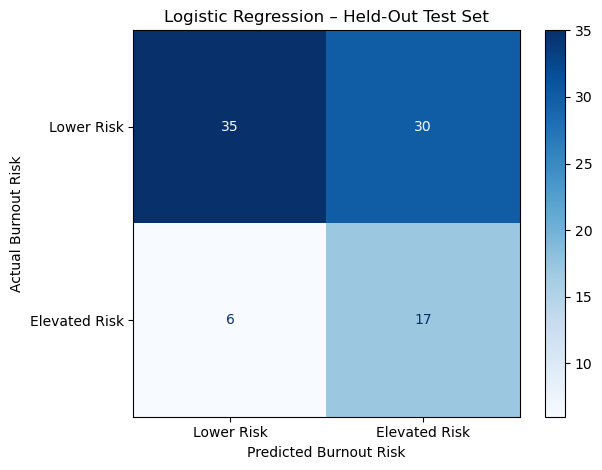

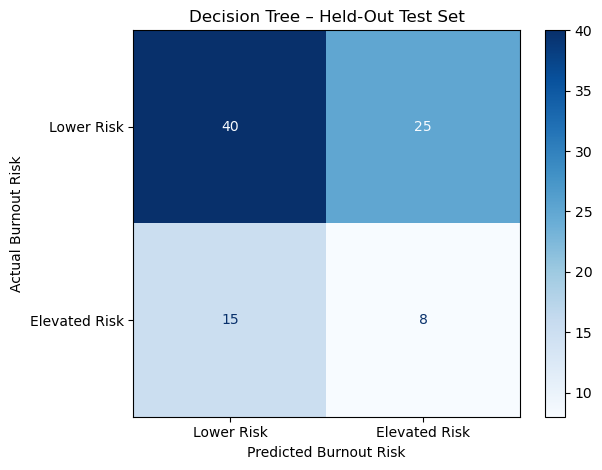

In [61]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

for model_name, model in tuned_models.items():

    y_pred = model.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=["Lower Risk", "Elevated Risk"],
        cmap="Blues",
        values_format="d"
    )

    plt.title(f"{model_name} – Held-Out Test Set")
    plt.xlabel("Predicted Burnout Risk")
    plt.ylabel("Actual Burnout Risk")
    plt.tight_layout()
    plt.show()

## Model Interpretability

### Logistic Regression Coefficients

# Note: six negatively worded CT items were reverse-scored in the original dataset.
# Coefficient directions are interpreted according to the authors' coded scoring.

In [62]:
# Extract feature names and coefficients from the tuned Logistic Regression model

final_lr = tuned_models["Logistic Regression"]

preprocessor = final_lr.named_steps["preprocessor"]
classifier = final_lr.named_steps["classifier"]

feature_names = preprocessor.get_feature_names_out()
coefficients = classifier.coef_[0]

lr_coefficients = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

# Remove preprocessing prefixes to make the names easier to read
lr_coefficients["Feature"] = (
    lr_coefficients["Feature"]
    .str.replace("numeric__", "", regex=False)
    .str.replace("ordinal__", "", regex=False)
    .str.replace("categorical__", "", regex=False)
)

lr_coefficients["Absolute_Coefficient"] = lr_coefficients["Coefficient"].abs()

lr_coefficients = (
    lr_coefficients
    .sort_values("Absolute_Coefficient", ascending=False)
    .reset_index(drop=True)
)

lr_coefficients.head(20)

,Feature,Coefficient,Absolute_Coefficient
0,CT - I missed being and interacting with students in the classroom in face-to-face teaching,-0.198270,0.198270
1,CT - Sinto-me sozinho na atuação no ensino remoto,-0.154993,0.154993
2,CT - I have support from people who live with me in my residence,-0.127260,0.127260
3,"Considering your conditions of access to technologies, such as computer or notebook, you evaluate that these conditions are:",-0.114779,0.114779
4,"CT - The process of evaluating learning, correcting and returning activities is more time-consuming in remote education",-0.106447,0.106447
5,CT - In my institution lack technological resources to develop activities in remote education,-0.103352,0.103352
6,"Considering your internet access conditions (cable and/or wi-fi), you assess that these conditions are:",-0.095778,0.095778
7,CT - My co-workers assist me in the activities necessary for remote teaching,-0.093254,0.093254
8,Amount resource that has access,-0.088536,0.088536
9,CT - I dedicate more hours for planning in remote education than in face-to-face teaching,-0.083548,0.083548


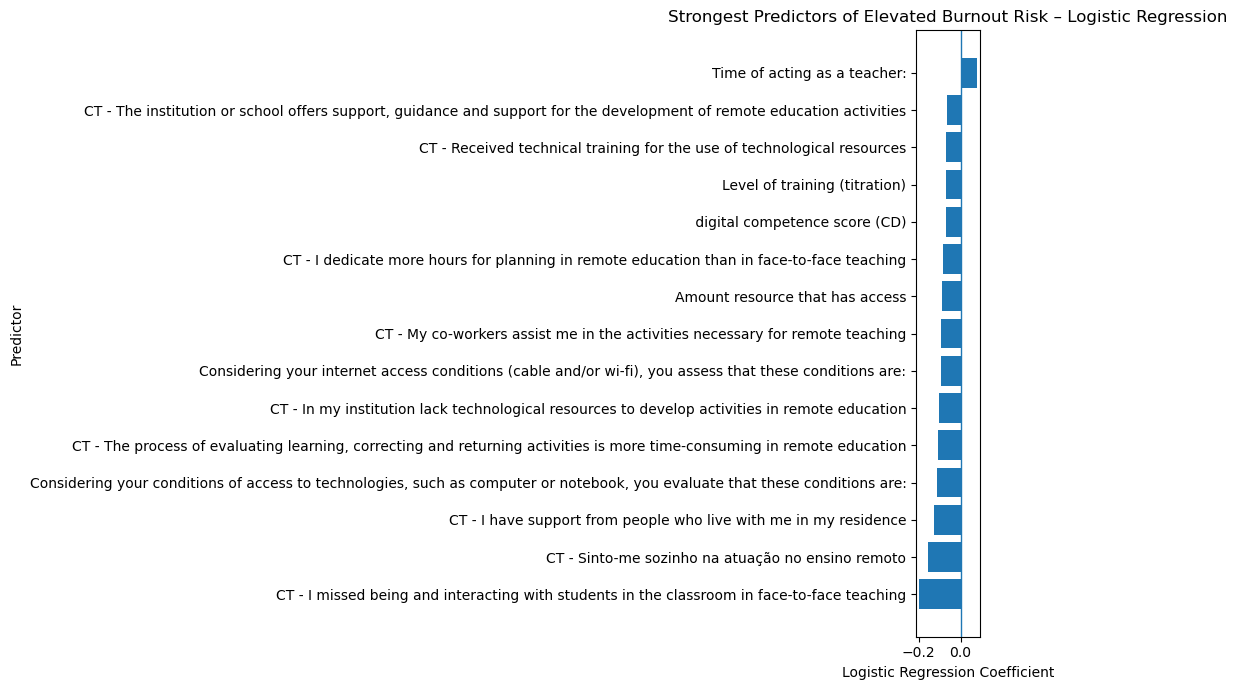

In [63]:
# Plot the strongest Logistic Regression coefficients

top_lr = lr_coefficients.head(15).sort_values("Coefficient")

plt.figure(figsize=(10, 7))

plt.barh(
    top_lr["Feature"],
    top_lr["Coefficient"]
)

plt.axvline(0, linewidth=1)

plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Predictor")
plt.title("Strongest Predictors of Elevated Burnout Risk – Logistic Regression")

plt.tight_layout()
plt.show()

### Predictor Coding Direction Validation

In [64]:
# Find variables that may contain the coding information

[name for name in dir() if "cod" in name.lower()]

['OneHotEncoder', 'codes', 'coding_info']

In [65]:
# Check coding information for the CT variables

ct_coding_check = coding_info[
    coding_info["Variable"].astype(str).str.startswith("CT -")
][["Variable", "Coding"]]

pd.set_option("display.max_colwidth", None)

ct_coding_check

,Variable,Coding
36,CT - I have support from people who live with me in my residence,"I totally disagree (1) - Partially disagree (2) - I do not agree, nor disagree (3) - Partially agree (4) - I totally agree (5)"
37,CT - My co-workers assist me in the activities necessary for remote teaching,NaN
38,"CT - The institution or school offers support, guidance and support for the development of remote education activities",NaN
39,CT - The technical(s) of the institution or school offers support for carrying out activities in the pandemic,NaN
40,CT - Received technical training for the use of technological resources,NaN
41,CT - I received pedagogical training to work in remote education,NaN
42,"CT - Participated in courses, lives and/ or lectures in addition to those offered by the institution(s) in which I work",NaN
43,CT - I dedicate more hours for planning in remote education than in face-to-face teaching,NaN
44,"CT - The process of evaluating learning, correcting and returning activities is more time-consuming in remote education",NaN
45,CT - I have difficulty using technological resources in remote education,NaN


In [66]:
# Check the notes stored in the coding sheet

coding_info.tail(5)

,Variable,Coding
57,QV [Gastrointestinal problems],NaN
58,QV [Muscle pain],NaN
59,Sum quality of life score (QV),Health total score
60,Have you had friends and/or close people who have contracted Covid 19?,Yes (1) No(2)
61,Have you lost any friends or close people by Covid 19?,NaN


In [67]:
codes

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,39,40,41,42,43,44,45,46,47,48,49,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82
0,Age:,Sex:,Marital status:,I live with:,Area of knowledge in which it operates:,Level of training (titration),Main level of education in which it operates:,Number of institutions or schools in which you act as a teacher:,The main institution(s) of activity are the network(s):,Official or contractual weekly workload:,Weekly workload effectively dedicated to work during pandemic,Time of acting as a teacher:,"Considering the devices and technological resources, indicate those to which you have (1) and do not have access (0): [Mobile]","Considering the devices and technological resources, indicate those you have (1) and do not have access (0): [Desktop computer]","Considerando os dispositivos e recursos tecnológicos, indique aqueles a que tem (1) e não tem acesso (0): [Computador portátil (notebook)]","Considerando os dispositivos e recursos tecnológicos, indique aqueles a que tem (1) e não tem acesso (0): [Tablet]",Amount resource that has access,"Considering the devices and technological resources, indicate those to which you have (1) and do not have access (0): [Home internet connection]","Considering the devices and technological resources, indicate those to which you have (1) and do not have access (0): [Internet connection by /on mobile]",Internet connection,"Considering your conditions of access to technologies, such as computer or notebook, you evaluate that these conditions are:","Considering your internet access conditions (cable and/or wi-fi), you assess that these conditions are:",Conditions of access devices and internet,CD [Email account],CD [Instant communicators (e.g. whatsapp)],"CD [Web conferencing or synchronous communication platform with video and sound (e.g. meet, zoom or skype)]","CD [Virtual learning environment (e.g. moodle, e-proinfo or google classroom)]","CD [Social networks (e.g. facebook, instagram or linkedin)]",CD [Applications for editing digital text (e.g. word or libreoffice)],CD [Visual editing tools (e.g. power point or canva)],CD [Tools for recording videos (e.g. digital cameras)],"CD [Tools for video editing (e.g. movavi, moviemaker or camtasia)]",CD [Tools or resources for online activities (e.g. online forum or questionnaire))],"CD [Tools for interactive presentation (e.g. kahoot, socrative or lied)]",digital competence score (CD),of new resources learned,CT - I have support from people who live with me in my residence,CT - My co-workers assist me in the activities necessary for remote teaching,"CT - The institution or school offers support, guidance and support for the development of remote education activities",CT - The technical(s) of the institution or school offers support for carrying out activities in the pandemic,CT - Received technical training for the use of technological resources,CT - I received pedagogical training to work in remote education,"CT - Participated in courses, lives and/ or lectures in addition to those offered by the institution(s) in which I work",CT - I dedicate more hours for planning in remote education than in face-to-face teaching,"CT - The process of evaluating learning, correcting and returning activities is more time-consuming in remote education",CT - I have difficulty using technological resources in remote education,CT - In my institution lack technological resources to develop activities in remote education,CT - Sinto-me sozinho na atuação no ensino remoto,CT - I missed being and interacting with students in the classroom in face-to-face teaching,working conditions (CT),QV [Sleep quality],QV [Amount of sleep hours],QV [Feed quality],QV [Body Weight],QV [Blood pressure],QV [Mood],QV [Anxiety],QV [Gastrointestinal problems],QV [Muscle pain],Sum quality of life score (QV),"MBI -1In the pandemic, I feel emotionally exh

In [68]:
# Show Excel files currently referenced in the notebook
%history -g ".xlsx"

942/77:
# Show Excel files currently referenced in the notebook
%history -g ".xlsx"
965/69:
# Show Excel files currently referenced in the notebook
%history -g ".xlsx"
  68:
# Show Excel files currently referenced in the notebook
%history -g ".xlsx"


In [69]:
# Check variables that may contain the original Excel file or workbook
[name for name in globals() if any(word in name.lower() for word in ["file", "path", "excel", "sheet", "data"])]

['__vsc_ipynb_file__', 'file_path', 'vif_data']

In [70]:
print(file_path)

/Users/cristinaabrahamse/Documents/Eduvos University/Data Science Honours /Early Prediction of Burnout (Honours Proj.)/Candidate Datasets/database_burnout_pandemia_brazil_translate.xlsx


In [71]:
# Check which variables were marked in red in the original coding sheet
from openpyxl import load_workbook

workbook = load_workbook(file_path, data_only=False)

print("Sheets:")
print(workbook.sheetnames)

Sheets:
['Data base', 'Subtitles (codes)', 'Open question']


In [72]:
# Find variable names marked in red in the coding sheet
ws = workbook["Subtitles (codes)"]

red_cells = []

for row in ws.iter_rows():
    for cell in row:
        if cell.value is not None and cell.font.color is not None:
            color = cell.font.color

            if color.type == "rgb" and color.rgb:
                red_cells.append((cell.coordinate, cell.value, color.rgb))

red_cells[:30]

[('A1', 'Age:', 'FF000000'),
 ('C1', 'Marital status:', 'FF000000'),
 ('D1', 'I live with:', 'FF000000'),
 ('E1', 'Area of knowledge in which it operates:', 'FF000000'),
 ('AR1',
  'CT - I dedicate more hours for planning in remote education than in face-to-face teaching',
  'FFFF0000'),
 ('AS1',
  'CT - The process of evaluating learning, correcting and returning activities is more time-consuming in remote education',
  'FFFF0000'),
 ('AT1',
  'CT - I have difficulty using technological resources in remote education',
  'FFFF0000'),
 ('AU1',
  'CT - In my institution lack technological resources to develop activities in remote education',
  'FFFF0000'),
 ('AV1', 'CT - Sinto-me sozinho na atuação no ensino remoto', 'FFFF0000'),
 ('AW1',
  'CT - I missed being and interacting with students in the classroom in face-to-face teaching',
  'FFFF0000'),
 ('BN1',
  "MBI -6I think I deal with my students' problems more effectively in remote teaching [-]",
  'FFFF0000'),
 ('BP1',
  'MBI -8I beli

In [73]:
# Variables explicitly marked as reverse-scored by the dataset authors

reverse_scored_variables = [
    (cell.coordinate, cell.value)
    for row in ws.iter_rows()
    for cell in row
    if cell.value is not None
    and cell.font.color is not None
    and cell.font.color.type == "rgb"
    and cell.font.color.rgb == "FFFF0000"
]

reverse_scored_variables

[('AR1',
  'CT - I dedicate more hours for planning in remote education than in face-to-face teaching'),
 ('AS1',
  'CT - The process of evaluating learning, correcting and returning activities is more time-consuming in remote education'),
 ('AT1',
  'CT - I have difficulty using technological resources in remote education'),
 ('AU1',
  'CT - In my institution lack technological resources to develop activities in remote education'),
 ('AV1', 'CT - Sinto-me sozinho na atuação no ensino remoto'),
 ('AW1',
  'CT - I missed being and interacting with students in the classroom in face-to-face teaching'),
 ('BN1',
  "MBI -6I think I deal with my students' problems more effectively in remote teaching [-]"),
 ('BP1',
  'MBI -8I believe that with my work I am positively influencing the lives of my students [+]'),
 ('BS1', 'MBI -11I feel very willing for my work in remote teaching [-]'),
 ('BV1',
  "MBI -14I didn't worry about what happens to some students during the pandemic [-]"),
 ('BX1',
  '

### Coding Direction Check

The original dataset coding sheet indicated that six negatively worded working-condition (CT) items were reverse-scored by the dataset authors. Consequently, coefficient directions for these variables were interpreted according to their coded scoring direction rather than the literal wording of the questionnaire item. No additional reverse-scoring was applied during modelling.

### Logistic Regression Coefficient Interpretation and Coding Direction

Inspection of the original dataset coding sheet confirmed that six negatively worded working-condition (CT) items were reverse-scored by the dataset authors. These included items relating to increased planning demands, time-consuming assessment activities, technological difficulties, lack of technological resources, social isolation during remote teaching, and missing face-to-face interaction with students.

The reverse scoring does not alter the fitted model or its performance results, as the model was trained using the coded values supplied in the dataset. However, the scoring direction must be considered when interpreting the Logistic Regression coefficients. For reverse-scored CT variables, the sign of the coefficient reflects the coded numerical direction rather than the literal wording of the questionnaire item.

For example, the strongest coefficient was observed for missing face-to-face interaction with students (β = -0.198). As this item was reverse-scored, the negative coefficient is consistent with greater loss of face-to-face interaction being associated with increased elevated-burnout risk. Similarly, perceived isolation during remote teaching was an important reverse-scored predictor (β = -0.155).

Among the non-reversed variables, greater support from people within the home environment was associated with lower elevated-burnout risk (β = -0.127). Overall, the Logistic Regression results suggest that social interaction, support, technological working conditions and remote-teaching demands contributed predictive information for distinguishing elevated burnout risk.

These relationships are predictive associations and should not be interpreted as causal effects.

## Decision Tree Interpretation

In [74]:
# Get the fitted Decision Tree and its transformed feature names

dt_final = dt_grid.best_estimator_

dt_preprocessor = dt_final.named_steps["preprocessor"]
dt_classifier = dt_final.named_steps["classifier"]

dt_feature_names = dt_preprocessor.get_feature_names_out()

dt_importance = pd.DataFrame({
    "Feature": dt_feature_names,
    "Importance": dt_classifier.feature_importances_
})

dt_importance = (
    dt_importance[dt_importance["Importance"] > 0]
    .sort_values("Importance", ascending=False)
    .reset_index(drop=True)
)

dt_importance

,Feature,Importance
0,ordinal__CT - Sinto-me sozinho na atuação no ensino remoto,0.313847
1,"ordinal__Considering your conditions of access to technologies, such as computer or notebook, you evaluate that these conditions are:",0.201263
2,"ordinal__CT - The process of evaluating learning, correcting and returning activities is more time-consuming in remote education",0.196047
3,numeric__ digital competence score (CD),0.178231
4,"ordinal__CT - Participated in courses, lives and/ or lectures in addition to those offered by the institution(s) in which I work",0.074623
5,ordinal__CT - I have support from people who live with me in my residence,0.035989


In [75]:
# Cleaner labels for the Decision Tree plot
pretty_names = {
    name: name
        .replace("numeric__", "")
        .replace("ordinal__", "")
        .replace("categorical__", "")
        .replace(
            "CT - Sinto-me sozinho na atuação no ensino remoto",
            "Feeling Alone During Remote Teaching"
        )
        .replace(
            "Considering your conditions of access to technologies, such as computer or notebook, you evaluate that these conditions are:",
            "Technology Access Conditions"
        )
        .replace(
            "CT - The process of evaluating learning, correcting and returning activities is more time-consuming in remote education",
            "Time-Consuming Assessment"
        )
        .replace(
            "CT - I have support from people who live with me in my residence",
            "Support at Home"
        )
        .replace(
            "digital competence score (CD)",
            "Digital Competence"
        )
        .replace(
            "CT - Participated in courses, lives and/ or lectures in addition to those offered by the institution(s) in which I work",
            "Additional Training Participation"
        )
    for name in dt_feature_names
}

clean_feature_names = [pretty_names[name] for name in dt_feature_names]

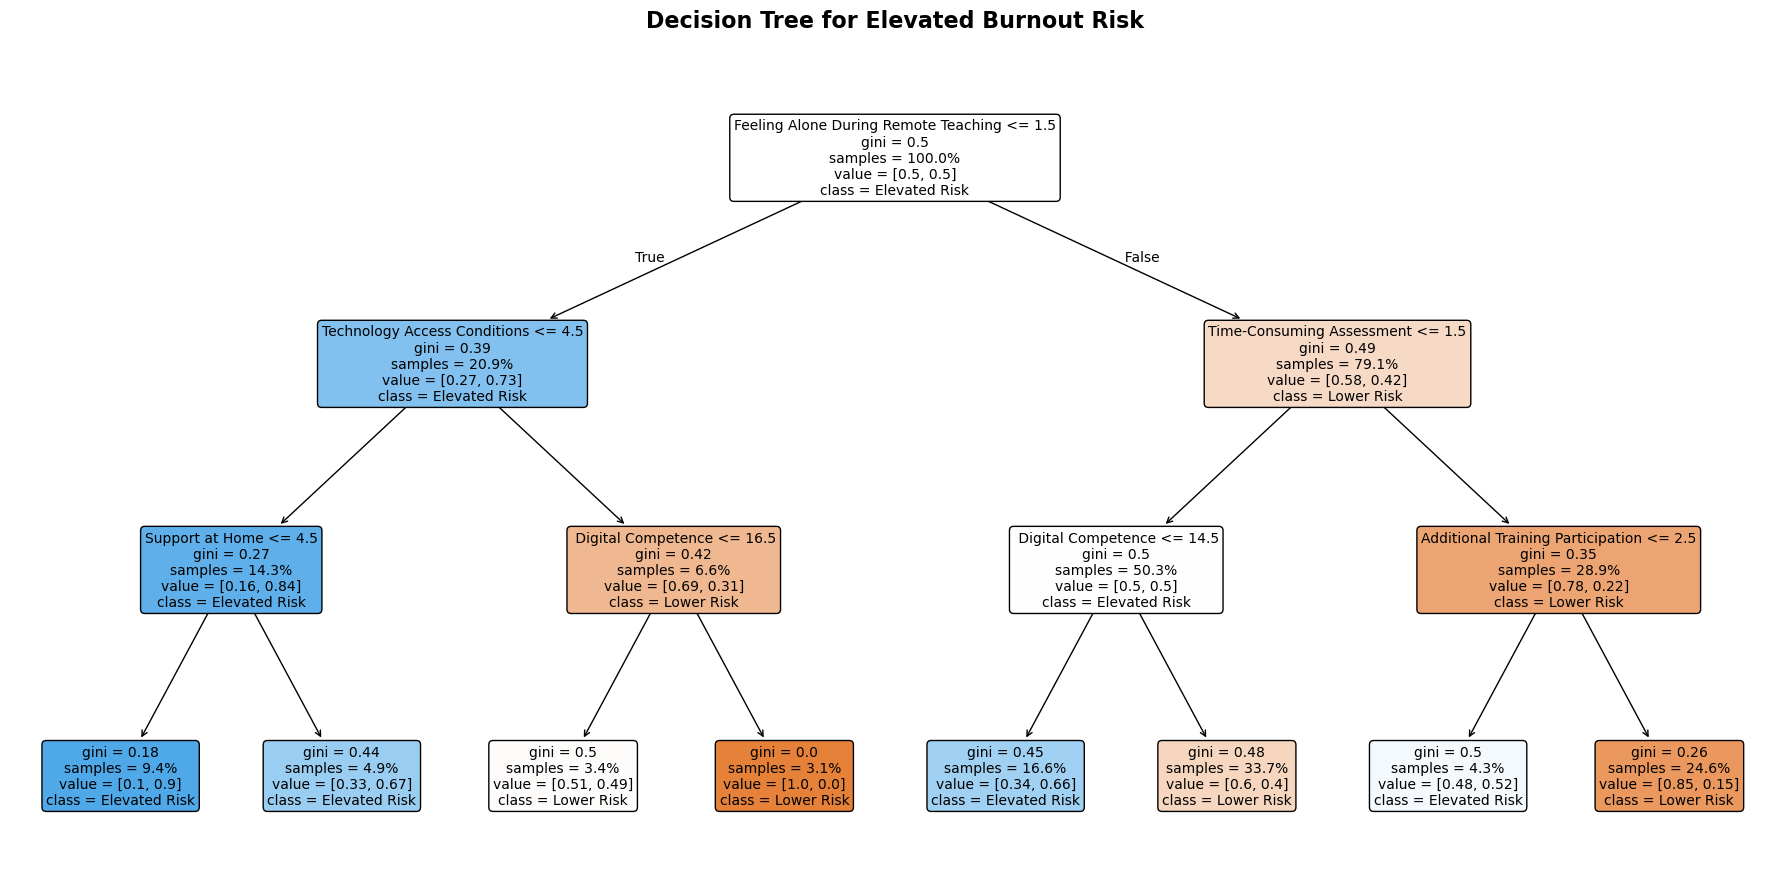

In [76]:
# Plot Decision Tree
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(18, 9))

plot_tree(
    dt_classifier,
    feature_names=clean_feature_names,
    class_names=["Lower Risk", "Elevated Risk"],
    filled=True,
    rounded=True,
    proportion=True,
    precision=2,
    fontsize=10
)

plt.title(
    "Decision Tree for Elevated Burnout Risk",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.tight_layout()
plt.show()

### Decision Tree Interpretation

The tuned Decision Tree produced a relatively simple decision structure with a maximum depth of three. Feeling alone during remote teaching formed the root split and had the highest feature importance (31.4%). Technology access conditions (20.1%), time-consuming assessment activities (19.6%) and digital competence (17.8%) also contributed substantially to the tree's decisions. Additional training participation and support within the home environment contributed smaller amounts.

Several of these variables relate to social support, technological working conditions and the demands associated with remote teaching. This broadly corresponds with patterns identified by the Logistic Regression model. Reverse-scored CT variables were interpreted according to the scoring direction documented by the dataset authors.

However, the Decision Tree demonstrated weak performance on the held-out test set (F1 = 0.286; ROC-AUC = 0.515). Therefore, its feature importance and decision pathways should be interpreted cautiously. They describe how the fitted tree generated its predictions but do not provide strong evidence that these decision rules generalise to unseen observations.

## Exploratory Data Analysis

### Distribution of Harmonised Burnout Scores

The distribution of Harmonised Burnout Scores (HBS) was examined to describe burnout levels within the teacher sample and visualise the threshold used to distinguish lower and elevated burnout risk.

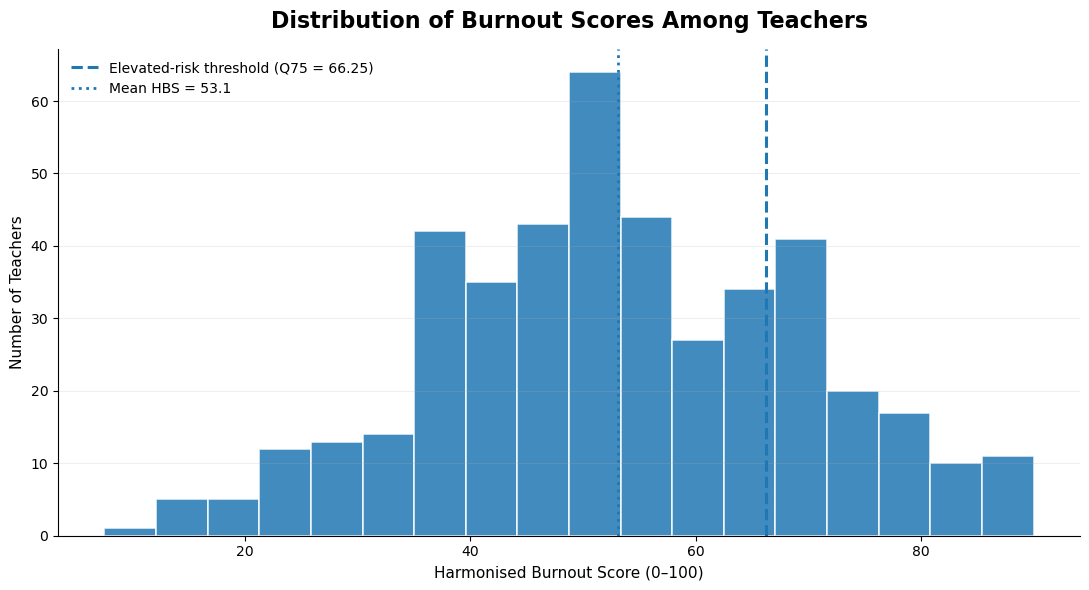

In [77]:
# Distribution of Harmonised Burnout Scores

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 6))

ax.hist(
    teachers["HBS"],
    bins=18,
    edgecolor="white",
    linewidth=1.2,
    alpha=0.85
)

# Elevated-risk threshold
ax.axvline(
    66.25,
    linestyle="--",
    linewidth=2.2,
    label="Elevated-risk threshold (Q75 = 66.25)"
)

# Mean HBS
mean_hbs = teachers["HBS"].mean()

ax.axvline(
    mean_hbs,
    linestyle=":",
    linewidth=2,
    label=f"Mean HBS = {mean_hbs:.1f}"
)

ax.set_title(
    "Distribution of Burnout Scores Among Teachers",
    fontsize=16,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Harmonised Burnout Score (0–100)", fontsize=11)
ax.set_ylabel("Number of Teachers", fontsize=11)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.grid(axis="y", alpha=0.2)
ax.legend(frameon=False)

plt.tight_layout()
plt.show()

**Interpretation:**  
Harmonised Burnout Scores varied considerably across the teacher sample, with a mean HBS of 53.1. The 75th-percentile threshold of 66.25 was used to classify elevated burnout risk. Teachers with scores at or above this threshold were assigned to the elevated-risk group, while those below the threshold were classified as lower risk. This threshold represents a dataset-relative risk classification rather than a clinical diagnostic cut-off.

In [78]:
# Find the DataFrame that contains HBS
for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame) and "HBS" in obj.columns:
        print(name, obj.shape)

teachers (438, 90)


In [79]:
# Compare key workplace factors by burnout-risk group

key_factors = [
    "CT - Sinto-me sozinho na atuação no ensino remoto",
    "Considering your conditions of access to technologies, such as computer or notebook, you evaluate that these conditions are:",
    "CT - The process of evaluating learning, correcting and returning activities is more time-consuming in remote education",
    "digital competence score (CD)",
    "CT - I have support from people who live with me in my residence"
]

factor_means = (
    teachers.groupby("Burnout_Risk")[key_factors]
    .mean()
    .T
)

factor_means.columns = ["Lower Risk", "Elevated Risk"]

factor_means.round(2)

KeyError: "Columns not found: 'digital competence score (CD)'"

In [ ]:
# Find the exact digital competence column name
[col for col in teachers.columns if "compet" in str(col).lower()]

[' digital competence score (CD)']

In [ ]:
# Remove the leading space from the digital competence column name
teachers = teachers.rename(columns={
    " digital competence score (CD)": "digital competence score (CD)"
})

print("digital competence score (CD)" in teachers.columns)

True


In [ ]:
# Effect sizes between lower and elevated burnout-risk groups

import numpy as np
import pandas as pd

lower = teachers[teachers["Burnout_Risk"] == 0]
elevated = teachers[teachers["Burnout_Risk"] == 1]

effect_sizes = []

for factor in key_factors:
    mean_lower = lower[factor].mean()
    mean_elevated = elevated[factor].mean()

    sd_lower = lower[factor].std()
    sd_elevated = elevated[factor].std()

    n_lower = lower[factor].count()
    n_elevated = elevated[factor].count()

    pooled_sd = np.sqrt(
        ((n_lower - 1) * sd_lower**2 +
         (n_elevated - 1) * sd_elevated**2)
        / (n_lower + n_elevated - 2)
    )

    cohens_d = (mean_elevated - mean_lower) / pooled_sd

    effect_sizes.append({
        "Factor": factor,
        "Lower Risk Mean": mean_lower,
        "Elevated Risk Mean": mean_elevated,
        "Cohens_d": cohens_d
    })

effect_sizes = pd.DataFrame(effect_sizes)

effect_sizes.round(3)

,Factor,Lower Risk Mean,Elevated Risk Mean,Cohens_d
0,CT - Sinto-me sozinho na atuação no ensino remoto,3.065,2.411,-0.484
1,"Considering your conditions of access to technologies, such as computer or notebook, you evaluate that these conditions are:",4.147,3.625,-0.569
2,"CT - The process of evaluating learning, correcting and returning activities is more time-consuming in remote education",1.752,1.482,-0.237
3,digital competence score (CD),15.890,14.571,-0.380
4,CT - I have support from people who live with me in my residence,4.129,3.580,-0.426


In [ ]:
# EDA figure
factor_labels = {
    "CT - Sinto-me sozinho na atuação no ensino remoto":
        "Feeling Alone During Remote Teaching",

    "Considering your conditions of access to technologies, such as computer or notebook, you evaluate that these conditions are:":
        "Technology Access Conditions",

    "CT - The process of evaluating learning, correcting and returning activities is more time-consuming in remote education":
        "Time-Consuming Assessment",

    "digital competence score (CD)":
        "Digital Competence",

    "CT - I have support from people who live with me in my residence":
        "Support at Home"
}

plot_effects = effect_sizes.copy()

plot_effects["Factor"] = plot_effects["Factor"].map(factor_labels)
plot_effects["Effect Size"] = plot_effects["Cohens_d"].abs()

plot_effects = plot_effects.sort_values("Effect Size")

In [ ]:
import plotly.express as px

interactive_effects = effect_sizes.copy()

interactive_effects["Factor"] = interactive_effects["Factor"].map(factor_labels)
interactive_effects["Effect Size"] = interactive_effects["Cohens_d"].abs()

interactive_effects = interactive_effects.sort_values(
    "Effect Size",
    ascending=True
)

fig = px.bar(
    interactive_effects,
    x="Effect Size",
    y="Factor",
    orientation="h",
    text="Effect Size",
    custom_data=[
        "Lower Risk Mean",
        "Elevated Risk Mean",
        "Cohens_d"
    ],
    title="Workplace Factors Differentiating Burnout-Risk Groups"
)

fig.update_traces(
    texttemplate="%{text:.2f}",
    textposition="outside",
    hovertemplate=(
        "<b>%{y}</b><br><br>"
        "Effect-size magnitude: %{x:.2f}<br>"
        "Lower-risk mean: %{customdata[0]:.2f}<br>"
        "Elevated-risk mean: %{customdata[1]:.2f}<br>"
        "Cohen's d: %{customdata[2]:.2f}"
        "<extra></extra>"
    )
)

fig.update_layout(
    template="plotly_white",
    title={
        "x": 0.5,
        "xanchor": "center",
        "font": {"size": 22}
    },
    xaxis_title="Absolute Cohen's d",
    yaxis_title="",
    height=520,
    margin=dict(l=30, r=70, t=90, b=60),
    hoverlabel=dict(font_size=13),
    showlegend=False
)

fig.update_xaxes(
    showgrid=True,
    gridcolor="rgba(0,0,0,0.08)",
    range=[0, 0.65]
)

fig.update_yaxes(
    showgrid=False
)

fig.show()

**Interpretation:**  
Technology access conditions showed the largest difference between lower- and elevated-risk teachers (|d| = 0.57), followed by feeling alone during remote teaching (|d| = 0.48), support at home (|d| = 0.43), digital competence (|d| = 0.38), and time-consuming assessment activities (|d| = 0.24). Elevated-risk teachers reported poorer technology access, lower digital competence and lower levels of support at home. The isolation and assessment items were reverse-scored in the original dataset and were therefore interpreted according to the authors' coded scoring direction. These effect sizes describe differences between the observed risk groups and do not imply causal relationships.

### Technology Access Across Burnout-Risk Groups

Technology access conditions were compared between lower- and elevated-burnout-risk teachers to examine the distribution of this workplace factor across the two risk groups.

In [ ]:

tech_access = (
    "Considering your conditions of access to technologies, "
    "such as computer or notebook, you evaluate that these conditions are:"
)

tech_plot = teachers[[tech_access, "Burnout_Risk"]].copy()

tech_plot["Burnout Risk"] = tech_plot["Burnout_Risk"].map({
    0: "Lower Risk",
    1: "Elevated Risk"
})

In [ ]:
# distribution of technology access by burnout-risk group

import plotly.express as px

fig = px.violin(
    tech_plot,
    x="Burnout Risk",
    y=tech_access,
    box=True,
    points="all",
    title="Technology Access Conditions by Burnout-Risk Group",
    labels={
        tech_access: "Technology Access Score",
        "Burnout Risk": "Burnout-Risk Group"
    },
    category_orders={
        "Burnout Risk": ["Lower Risk", "Elevated Risk"]
    }
)

fig.update_traces(
    jitter=0.18,
    marker=dict(size=4, opacity=0.35),
    hovertemplate=(
        "<b>%{x}</b><br>"
        "Technology access score: %{y}<extra></extra>"
    )
)

fig.update_layout(
    template="plotly_white",
    title={
        "x": 0.5,
        "xanchor": "center",
        "font": {"size": 22}
    },
    height=600,
    xaxis_title="Burnout-Risk Group",
    yaxis_title="Technology Access Score",
    showlegend=False,
    margin=dict(l=70, r=50, t=90, b=70)
)

fig.update_yaxes(
    dtick=1,
    showgrid=True,
    gridcolor="rgba(0,0,0,0.08)"
)

fig.show()

**Interpretation:**  
Technology access conditions differed between the burnout-risk groups. Lower-risk teachers reported a mean technology access score of 4.15, compared with 3.63 among elevated-risk teachers. The difference represented a moderate effect (Cohen's d = -0.57), with the distribution showing generally poorer technology access conditions among teachers classified as having elevated burnout risk. This finding is consistent with the Decision Tree, in which technology access was one of the more influential variables. The observed relationship represents an association within this sample and should not be interpreted as causal.

## Final Model Comparison

The final tuned Logistic Regression and Decision Tree models were compared using performance on the held-out test set.

In [ ]:
# Final held-out model performance

model_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Logistic Regression": [
        0.591,
        0.362,
        0.739,
        0.486,
        0.677
    ],
    "Decision Tree": [
        0.545,
        0.242,
        0.348,
        0.286,
        0.515
    ]
})

model_results

,Metric,Logistic Regression,Decision Tree
0,Accuracy,0.591,0.545
1,Precision,0.362,0.242
2,Recall,0.739,0.348
3,F1 Score,0.486,0.286
4,ROC-AUC,0.677,0.515


In [ ]:
# Comparison of final model performance

import plotly.graph_objects as go

metrics = model_results["Metric"].tolist()

lr_scores = model_results["Logistic Regression"].tolist()
dt_scores = model_results["Decision Tree"].tolist()

fig = go.Figure()

fig.add_trace(go.Scatterpolar(
    r=lr_scores + [lr_scores[0]],
    theta=metrics + [metrics[0]],
    fill="toself",
    name="Logistic Regression",
    hovertemplate="%{theta}: %{r:.3f}<extra>Logistic Regression</extra>"
))

fig.add_trace(go.Scatterpolar(
    r=dt_scores + [dt_scores[0]],
    theta=metrics + [metrics[0]],
    fill="toself",
    name="Decision Tree",
    hovertemplate="%{theta}: %{r:.3f}<extra>Decision Tree</extra>"
))

fig.update_layout(
    template="plotly_white",

    title={
        "text": "Final Held-Out Model Performance",
        "x": 0.5,
        "xanchor": "center",
        "font": {"size": 22}
    },

    polar=dict(
        radialaxis=dict(
            visible=True,
            range=[0, 1],
            tickformat=".1f"
        )
    ),

    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=-0.15,
        xanchor="center",
        x=0.5
    ),

    height=650,
    margin=dict(l=80, r=80, t=100, b=100)
)

fig.show()

**Interpretation:**  
The Logistic Regression model demonstrated stronger held-out performance than the Decision Tree across all evaluated metrics. Logistic Regression achieved an accuracy of 0.591, precision of 0.362, recall of 0.739, F1 score of 0.486 and ROC-AUC of 0.677. Its comparatively high recall indicates that the model identified a substantial proportion of teachers classified as having elevated burnout risk, although the lower precision indicates that a number of lower-risk teachers were incorrectly classified as elevated risk.

The Decision Tree achieved an accuracy of 0.545, precision of 0.242, recall of 0.348, F1 score of 0.286 and ROC-AUC of 0.515. Its ROC-AUC was close to chance-level discrimination, indicating limited ability to distinguish between the two burnout-risk groups on unseen data.

Overall, Logistic Regression provided the stronger predictive performance for this dataset, particularly for identifying elevated-risk cases. However, its moderate ROC-AUC and relatively low precision indicate that its predictive performance remained limited and should be interpreted as an early-risk screening result rather than a diagnostic classification.

## Dataset 3 Summary

The Brazil teacher dataset contained 438 participants and provided a documented MBI-derived burnout outcome alongside demographic, occupational, technological and remote-working-condition variables. The supplied MBI final score was transformed to the common 0–100 Harmonised Burnout Score (HBS), with the 75th percentile (66.25) used to identify elevated burnout risk. This resulted in 112 teachers (25.6%) being classified as elevated risk and 326 (74.4%) as lower risk.

Following LLM-assisted semantic mapping and researcher validation, 29 predictors were retained for modelling. Logistic Regression and Decision Tree classifiers were evaluated using baseline cross-validation, hyperparameter tuning and a held-out test set.

On the held-out test data, Logistic Regression achieved an accuracy of 0.591, precision of 0.362, recall of 0.739, F1 score of 0.486 and ROC-AUC of 0.677. The Decision Tree achieved an accuracy of 0.545, precision of 0.242, recall of 0.348, F1 score of 0.286 and ROC-AUC of 0.515. Logistic Regression therefore demonstrated stronger predictive performance across the evaluated metrics, particularly in its ability to identify elevated-risk cases.

Interpretability analysis highlighted variables associated with social interaction and support, technology access and digital competence, and remote-teaching working conditions. Technology access also showed the largest observed difference among the selected workplace factors between the two burnout-risk groups (|d| = 0.57). Several negatively worded working-condition items were documented by the original dataset authors as reverse-scored, and their model coefficients and decision-tree splits were interpreted according to this coded direction.

Overall, the findings indicate that the dataset contained meaningful workplace information for early burnout-risk prediction, although predictive performance was moderate and varied substantially between the two interpretable modelling approaches. The pandemic-specific teaching context should also be considered when assessing the generalisability of these findings.

### Elevated-Risk Case Detection

Within the held-out test sample of 88 teachers, 23 participants were classified as having elevated burnout risk based on the HBS threshold. The Logistic Regression model correctly identified 17 of these 23 elevated-risk cases and missed 6, corresponding to a recall of 73.9%.

The model predicted 47 participants as elevated risk overall, of whom 17 were correctly classified and 30 were false positives. Therefore, although the model demonstrated relatively strong sensitivity for detecting elevated-risk participants, its lower precision (36.2%) indicates that this sensitivity was accompanied by a relatively high number of false-positive classifications.

For an early-risk screening context, this result demonstrates the model's ability to identify a substantial proportion of elevated-risk cases while also highlighting the trade-off between sensitivity and precision.

### Logistic Regression Statistical Inference

A separate inferential Logistic Regression analysis was conducted to complement the predictive modelling results. The researcher-validated predictor set used in the primary modelling analysis was retained.

Coefficients, odds ratios, 95% confidence intervals and p-values were estimated to examine adjusted associations between individual predictors and elevated burnout risk. Statistical significance was assessed at p < 0.05 and interpreted as supplementary to predictive performance and model interpretability rather than as evidence of causality.

In [ ]:
# Check sample completeness before inferential Logistic Regression

inference_check = X[final_predictors].copy()
inference_check["Burnout_Risk"] = y

complete_inference = inference_check.dropna()

print("Original sample size:", len(inference_check))
print("Complete-case sample size:", len(complete_inference))
print("Observations removed:", len(inference_check) - len(complete_inference))

print("\nComplete-case outcome distribution:")
print(
    complete_inference["Burnout_Risk"]
    .value_counts()
    .sort_index()
)

print("\nPredictors with missing values:")
print(
    inference_check[final_predictors]
    .isna()
    .sum()
    .loc[lambda x: x > 0]
    .sort_values(ascending=False)
)

Original sample size: 438
Complete-case sample size: 431
Observations removed: 7

Complete-case outcome distribution:
Burnout_Risk
0    321
1    110
Name: count, dtype: int64

Predictors with missing values:
0
Age:                                                                                                             5
CT - The technical(s) of the institution or school offers support for carrying out activities in the pandemic    1
CT - Sinto-me sozinho na atuação no ensino remoto                                                                1
dtype: int64


In [ ]:
# Check categorical group sizes and burnout-risk distribution
# before dummy coding for inferential Logistic Regression

for column in categorical_predictors:
    print(f"\n{'='*80}")
    print(column)
    print("="*80)

    print(
        pd.crosstab(
            complete_inference[column],
            complete_inference["Burnout_Risk"],
            margins=True
        )
    )


Sex:
Burnout_Risk    0    1  All
Sex:                       
1             238   85  323
2              83   25  108
All           321  110  431

Area of knowledge in which it operates:
Burnout_Risk                               0    1  All
Area of knowledge in which it operates:               
1                                        118   42  160
2                                         19    9   28
3                                         75   27  102
4                                         14    4   18
5                                         57   18   75
6                                          2    0    2
7                                         16    5   21
8                                         20    5   25
All                                      321  110  431

The main institution(s) of activity are the network(s):
Burnout_Risk                                               0    1  All
The main institution(s) of activity are the network(s):               
1        

#### Sparse Category Handling

Category frequencies were examined prior to inferential Logistic Regression. One area-of-knowledge category contained only two observations, both of which belonged to the lower-risk group. This extremely sparse category presented a risk of complete separation and unstable maximum-likelihood estimation.

The two observations belonging to this category were therefore excluded from the inferential analysis only. No categories were combined because the substantive meaning of the coded category did not justify reassignment to another group. This adjustment did not affect the primary predictive modelling analysis.

In [ ]:
# Remove the extremely sparse area-of-knowledge category
# for inferential analysis only

teacher_inference = complete_inference[
    complete_inference[
        "Area of knowledge in which it operates:"
    ] != 6
].copy()

print("Final inferential sample size:",
      len(teacher_inference))

print("\nOutcome distribution:")
print(
    teacher_inference["Burnout_Risk"]
    .value_counts()
    .sort_index()
)

Final inferential sample size: 431

Outcome distribution:
Burnout_Risk
0    321
1    110
Name: count, dtype: int64


In [ ]:
print(
    complete_inference[
        "Area of knowledge in which it operates:"
    ].value_counts(dropna=False)
)

print("\nData type:")
print(
    complete_inference[
        "Area of knowledge in which it operates:"
    ].dtype
)

Area of knowledge in which it operates:
1    160
3    102
5     75
2     28
8     25
7     21
4     18
6      2
Name: count, dtype: int64

Data type:
object


In [ ]:
# Remove the extremely sparse area-of-knowledge category
# for inferential analysis only

teacher_inference = complete_inference[
    complete_inference[
        "Area of knowledge in which it operates:"
    ].astype(str) != "6"
].copy()

print("Final inferential sample size:",
      len(teacher_inference))

print("\nOutcome distribution:")
print(
    teacher_inference["Burnout_Risk"]
    .value_counts()
    .sort_index()
)

Final inferential sample size: 429

Outcome distribution:
Burnout_Risk
0    319
1    110
Name: count, dtype: int64


In [ ]:
# Prepare predictors for inferential Logistic Regression

X_teacher_inference = teacher_inference[
    final_predictors
].copy()

y_teacher_inference = teacher_inference[
    "Burnout_Risk"
].astype(int)

# Convert categorical predictors to strings
for col in categorical_predictors:
    X_teacher_inference[col] = (
        X_teacher_inference[col].astype(str)
    )

# Set explicit reference categories
X_teacher_inference["Sex:"] = pd.Categorical(
    X_teacher_inference["Sex:"],
    categories=["1", "2"]
)

X_teacher_inference[
    "Area of knowledge in which it operates:"
] = pd.Categorical(
    X_teacher_inference[
        "Area of knowledge in which it operates:"
    ],
    categories=["1", "2", "3", "4", "5", "7", "8"]
)

X_teacher_inference[
    "The main institution(s) of activity are the network(s):"
] = pd.Categorical(
    X_teacher_inference[
        "The main institution(s) of activity are the network(s):"
    ],
    categories=["2", "1", "1, 2"]
)

# Create dummy variables
X_teacher_inference = pd.get_dummies(
    X_teacher_inference,
    columns=categorical_predictors,
    drop_first=True,
    dtype=float
)

# Ensure everything is numeric
X_teacher_inference = X_teacher_inference.astype(float)

print("Final inferential sample size:", len(X_teacher_inference))
print("Number of predictors after dummy coding:",
      X_teacher_inference.shape[1])

print("\nAny missing values:",
      X_teacher_inference.isna().sum().sum())

print("\nPredictor columns:")
for col in X_teacher_inference.columns:
    print("-", col)

Final inferential sample size: 429
Number of predictors after dummy coding: 35

Any missing values: 0

Predictor columns:
- Age:
- Level of training (titration)
- Main level of education in which it operates:
- Number of institutions or schools in which you act as a teacher:
- Official or contractual weekly workload:
- Weekly workload effectively dedicated to work during pandemic
- Time of acting as a teacher:
- Amount resource that has access
- Internet connection
- Considering your conditions of access to technologies, such as computer or notebook, you evaluate that these conditions are:
- Considering your internet access conditions (cable and/or wi-fi), you assess that these conditions are:
-  digital competence score (CD)
-  of new resources learned
- CT - I have support from people who live with me in my residence
- CT - My co-workers assist me in the activities necessary for remote teaching
- CT - The institution or school offers support, guidance and support for the development 

In [ ]:
import statsmodels.api as sm

# Add intercept
X_teacher_inference_sm = sm.add_constant(
    X_teacher_inference
)

# Fit inferential Logistic Regression
teacher_inferential_lr = sm.Logit(
    y_teacher_inference,
    X_teacher_inference_sm
).fit(maxiter=100)

print(teacher_inferential_lr.summary())

Optimization terminated successfully.
         Current function value: 0.461958
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:           Burnout_Risk   No. Observations:                  429
Model:                          Logit   Df Residuals:                      393
Method:                           MLE   Df Model:                           35
Date:                Wed, 07 Oct 2026   Pseudo R-squ.:                  0.1885
Time:                        13:08:18   Log-Likelihood:                -198.18
converged:                       True   LL-Null:                       -244.22
Covariance Type:            nonrobust   LLR p-value:                 5.018e-07
                                                                                                                                   coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------

In [ ]:
# Create inferential results table for teacher dataset

teacher_ci = teacher_inferential_lr.conf_int()

teacher_inference_results = pd.DataFrame({
    "Predictor": teacher_inferential_lr.params.index,
    "Coefficient": teacher_inferential_lr.params.values,
    "Odds Ratio": np.exp(teacher_inferential_lr.params.values),
    "CI Lower": np.exp(teacher_ci[0].values),
    "CI Upper": np.exp(teacher_ci[1].values),
    "p-value": teacher_inferential_lr.pvalues.values
})

# Remove intercept
teacher_inference_results = teacher_inference_results[
    teacher_inference_results["Predictor"] != "const"
].copy()

teacher_inference_results["Significant (p < 0.05)"] = np.where(
    teacher_inference_results["p-value"] < 0.05,
    "Yes",
    "No"
)

teacher_inference_results["95% CI for OR"] = (
    teacher_inference_results["CI Lower"].map("{:.3f}".format)
    + " – "
    + teacher_inference_results["CI Upper"].map("{:.3f}".format)
)

teacher_inference_table = teacher_inference_results[
    [
        "Predictor",
        "Coefficient",
        "Odds Ratio",
        "95% CI for OR",
        "p-value",
        "Significant (p < 0.05)"
    ]
]

display(
    teacher_inference_table.style
    .format({
        "Coefficient": "{:.3f}",
        "Odds Ratio": "{:.3f}",
        "p-value": lambda x: "<0.001" if x < 0.001 else f"{x:.3f}"
    })
    .background_gradient(
        subset=["Odds Ratio"],
        cmap="Blues"
    )
    .set_caption(
        "Inferential Logistic Regression Results – Brazilian Teacher Sample"
    )
    .hide(axis="index")
)

Predictor,Coefficient,Odds Ratio,95% CI for OR,p-value,Significant (p < 0.05)
Age:,-0.004,0.996,0.957 – 1.036,0.833,No
Level of training (titration),-0.257,0.774,0.547 – 1.093,0.146,No
Main level of education in which it operates:,0.180,1.197,0.910 – 1.574,0.199,No
Number of institutions or schools in which you act as a teacher:,0.096,1.100,0.715 – 1.695,0.664,No
Official or contractual weekly workload:,-0.287,0.750,0.561 – 1.004,0.053,No
Weekly workload effectively dedicated to work during pandemic,0.225,1.253,1.012 – 1.551,0.038,Yes
Time of acting as a teacher:,0.114,1.121,0.805 – 1.559,0.499,No
Amount resource that has access,-0.131,0.877,0.586 – 1.314,0.526,No
Internet connection,-0.043,0.958,0.437 – 2.103,0.915,No
"Considering your conditions of access to technologies, such as computer or notebook, you evaluate that these conditions are:",-0.273,0.761,0.526 – 1.102,0.149,No


#### Statistical Interpretation

The inferential Logistic Regression model was statistically significant overall (likelihood-ratio p < 0.001), indicating that the predictor set collectively showed evidence of association with elevated burnout risk.

Four predictors demonstrated statistically significant adjusted associations at p < 0.05. Weekly workload effectively dedicated to work during the pandemic showed a positive association with elevated burnout risk (β = 0.226, p = 0.038). Support from people living in the respondent's residence showed a negative association (β = -0.232, p = 0.025). Feeling alone while working in remote teaching (β = -0.244, p = 0.032) and missing face-to-face interaction with students (β = -0.656, p = 0.002) also showed negative adjusted associations with elevated burnout risk.

Official or contractual weekly workload approached but did not meet the predefined significance threshold (p = 0.053). The remaining predictors were not statistically significant after multivariable adjustment.

The direction of each coefficient reflects the coding and scale of the corresponding variable and should therefore be interpreted in relation to the original questionnaire response coding. These results represent adjusted statistical associations rather than causal effects and are supplementary to the primary predictive modelling results.